# Multivariate Time Series Models I: Vector Autoregressions
**HS 821 · Lecture 14 · Topics in Time Series Econometrics**

**Sunil Paul**

November 2026 · R 4.6

A univariate model can describe each series, but it cannot say how a disturbance to one series is transmitted to another. This lecture introduces the workhorse model for that question, the **vector autoregression** (VAR) of Sims (1980), following Enders (2015, Ch. 5). It has two parts.

| Part | Sections | What it covers |
|---|---|---|
| **I. The reduced-form VAR** | 1–8 | why model series jointly; from the structural VAR to the reduced form; stability; the Wold (VMA) representation; estimation, lag length and diagnostics; Granger causality and forecasting; **Application I** |
| **II. Identification and innovation accounting** | 9–14 | the identification problem; recursive (Cholesky) identification; impulse responses, variance and historical decompositions; a worked example; non-recursive and calibrated restrictions; **Application II** |

Part I needs nothing beyond the data: the reduced form is estimated by OLS, and it is enough for describing the data and for forecasting. Part II asks the question the reduced form cannot answer on its own — how the variables respond to a **structural** shock — and shows that every answer rests on an identifying assumption.

Both applications use the same data, quarterly US industrial production growth and CPI inflation (`varQ11.csv`; Enders 2015, Ch. 5, Question 11). The lecture ends with a summary, exercises, suggested reading and an R quick reference (Appendix A).

## Notation


| Object | Symbol | Notes |
|---|---|---|
| Vector of $k$ endogenous variables | $X_t$ | $k\times 1$; in the bivariate examples $X_t=(Y_t,Z_t)'$ |
| Structural VAR | $B X_t = \Gamma_0 + \Gamma_1 X_{t-1} + \cdots + \Gamma_p X_{t-p} + \varepsilon_t$ | $B$ has ones on its diagonal |
| Structural shocks | $\varepsilon_t$, $\;E(\varepsilon_t\varepsilon_t') = D$ | $D$ diagonal; bivariate: $D=\operatorname{diag}(\sigma_{\varepsilon y}^2,\sigma_{\varepsilon z}^2)$ |
| Reduced-form VAR | $X_t = A_0 + A_1 X_{t-1} + \cdots + A_p X_{t-p} + e_t$ | $A_i = B^{-1}\Gamma_i$ |
| Reduced-form errors | $e_t = B^{-1}\varepsilon_t$, $\;E(e_te_t') = \Sigma_e$ | correlated across equations; bivariate elements $\sigma_1^2$, $\sigma_2^2$, $\sigma_{12}$ |
| Orthonormal structural shocks | $u_t = D^{-1/2}\varepsilon_t$, $\;E(u_tu_t') = I$ | "one-standard-deviation" shocks |
| Impact matrix | $P = B^{-1}D^{1/2}$, so $e_t = P u_t$ and $\Sigma_e = PP'$ | the object identification pins down |
| Reduced-form VMA coefficients | $\Phi_h$ ($\Phi_0 = I$) | $X_t = \mu + \sum_h \Phi_h e_{t-h}$ |
| Structural IRFs, unit shock | $\Psi_h = \Phi_h B^{-1}$ | response to $\varepsilon_t$ |
| Structural IRFs, one-s.d. shock | $\Theta_h = \Phi_h P = \Psi_h D^{1/2}$ | response to $u_t$; what `vars::irf()` reports |
| Lag polynomial at $L=1$ | $A(1) = I - A_1 - \cdots - A_p$ | used for means and long-run effects |

**Sign convention.** Following Enders (2015), the off-diagonal elements of $B$ enter the structural equations with a *minus* sign, e.g. $Y_t = b_{10} - b_{12}Z_t + \cdots$, so that they appear with a plus sign in $B$. Some texts and software write $Y_t=b_{12}Z_t+\cdots$ instead, which flips the sign of the off-diagonal elements of $B$; the economics is unchanged as long as one convention is used throughout.

## Setup

Most of this lecture is algebra. The R code checks it — every number in the worked examples can be reproduced by hand, and the cell after each derivation does exactly that — and runs the two applications. We keep `roots_plot()` from Lectures 6–10 and add five helpers:

- `vma()` — the VMA matrices $\Phi_0,\Phi_1,\dots$ of a VAR with known coefficients (Section 5);
- `fevd_table()` — a forecast-error variance decomposition from one-s.d. structural responses $\Theta_h$ (Section 11);
- `irf_grid()` — impulse responses in a grid, one panel per variable and shock, with optional confidence bands;
- `irf_array()` — converts the output of `vars::irf()` into the arrays that `irf_grid()` plots;
- `hist_decomp()` — the historical decomposition of a fitted VAR (Section 11), which **vars** does not provide.

Estimation uses the **vars** package (Pfaff 2008): `VARselect()`, `VAR()`, `roots()`, `serial.test()`, `causality()`, `predict()`, `irf()`, `fevd()` and `SVAR()`. Loading **vars** also loads **urca**, whose `ur.df()` we used in Lecture 10.

In [3]:
# ------------------------------------------------------------------
# Setup: one plotting helper from Lectures 6-10 + five new ones for VARs
# ------------------------------------------------------------------
# install.packages(c("vars", "ggplot2", "gridExtra"))   # run once if needed
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
  library(vars)        # VARselect, VAR, roots, serial.test, causality, irf, fevd, SVAR (Pfaff 2008); loads urca
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Roots of a lag polynomial on the complex plane, with the unit circle.
# Roots on the circle (|z| = 1 up to rounding) get their own colour.
roots_plot <- function(roots, title = NULL, tol = 1e-6) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  where <- ifelse(abs(Mod(roots) - 1) < tol, "on the circle",
                  ifelse(Mod(roots) > 1, "outside", "inside"))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots), where = where)
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = where), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red",
                                   `on the circle` = "blue"), name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. VMA (Wold) matrices: Phi_0 = I, Phi_j = sum_{i=1}^{min(j,p)} A_i Phi_{j-i}.
# 'A' is a list of k x k matrices A_1, ..., A_p. Returns a k x k x (h+1) array; [, , j+1] is Phi_j.
vma <- function(A, h = 20) {
  k <- nrow(A[[1]]); p <- length(A)
  Phi <- array(0, c(k, k, h + 1)); Phi[, , 1] <- diag(k)
  for (j in seq_len(h)) for (i in seq_len(min(j, p)))
    Phi[, , j + 1] <- Phi[, , j + 1] + A[[i]] %*% Phi[, , j - i + 1]
  Phi
}

# NEW. Forecast-error variance decomposition from one-s.d. structural responses
# Theta[i, j, h + 1] (variable i, shock j, horizon h). For each n-step horizon: the forecast-error
# variance sum_{h < n} sum_j theta_ij,h^2 and the percentage contributed by each shock.
fevd_table <- function(Theta, horizons, vars = c("Y", "Z"), shocks = c("eps_y", "eps_z")) {
  k    <- dim(Theta)[1]
  grid <- expand.grid(n = horizons, i = seq_len(k))
  res  <- t(mapply(function(n, i) {
    contrib <- rowSums(matrix(Theta[i, , 1:n]^2, nrow = k))
    c(sum(contrib), 100 * contrib / sum(contrib))
  }, grid$n, grid$i))
  out <- data.frame(vars[grid$i], grid$n, round(res[, 1], 4), round(res[, -1, drop = FALSE], 1))
  names(out) <- c("variable", "n-step", "FEV", paste("%", shocks))
  out
}

# NEW. Impulse responses in a k x k grid: rows = responding variable, columns = shock.
# 'irfs' is a named list of k x k x (H+1) arrays [variable, shock, horizon], one line each.
# Optional 'lower' and 'upper' arrays of the same shape add a shaded band.
irf_grid <- function(irfs, vars = c("Y", "Z"), shocks = c("shock 1", "shock 2"), title = NULL,
                     lower = NULL, upper = NULL, xlab = "Horizon", ylab = "Response") {
  to_df <- function(a) {
    g <- expand.grid(i = seq_along(vars), j = seq_along(shocks), h = seq_len(dim(a)[3]))
    data.frame(response = factor(paste("Response of", vars[g$i]),
                                 levels = paste("Response of", vars)),
               shock    = factor(shocks[g$j], levels = shocks),
               horizon  = g$h - 1, value = a[cbind(g$i, g$j, g$h)])
  }
  lines <- do.call(rbind, lapply(names(irfs), function(nm) cbind(to_df(irfs[[nm]]), series = nm)))
  lines$series <- factor(lines$series, levels = names(irfs))
  m <- length(irfs)
  p <- ggplot(lines, aes(horizon, value)) + theme_classic()
  if (!is.null(lower)) {
    band <- cbind(to_df(lower), upper = to_df(upper)$value)
    p <- p + geom_ribbon(data = band, aes(x = horizon, ymin = value, ymax = upper),
                         inherit.aes = FALSE, fill = "grey85")
  }
  p + geom_hline(yintercept = 0, colour = "grey60") +
    geom_line(aes(colour = series, linetype = series)) +
    facet_grid(response ~ shock, scales = "free_y") +
    scale_colour_manual(values = c("black", "red", "blue", "darkgreen")[1:m], name = NULL) +
    scale_linetype_manual(values = c("solid", "dashed", "dotted", "dotdash")[1:m], name = NULL) +
    scale_x_continuous(breaks = seq(0, dim(irfs[[1]])[3] - 1, by = 4)) +
    labs(x = xlab, y = ylab, title = title) +
    theme(legend.position = if (m > 1) "bottom" else "none",
          legend.key.width = unit(1.2, "cm"),
          legend.text = element_text(margin = margin(r = 12)))
}

# NEW. Convert vars::irf() output (a list of horizon x variable matrices, one per shock) into a
# k x k x (H+1) array [variable, shock, horizon]. 'what' is "irf", "Lower" or "Upper".
irf_array <- function(ir, what = "irf") {
  x <- ir[[what]]; shocks <- names(x); vars <- colnames(x[[1]])
  a <- array(NA_real_, c(length(vars), length(shocks), nrow(x[[1]])),
             dimnames = list(vars, shocks, NULL))
  for (j in seq_along(shocks)) a[, j, ] <- t(x[[shocks[j]]])
  a
}

# NEW. Historical decomposition of a fitted vars::VAR() with intercepts, given an impact matrix P
# (Sigma_e = P P'). Returns the data, the baseline (the VAR iterated forward from the first p
# observations with every shock set to zero) and contrib[t, variable, shock], the cumulated
# effect of each structural shock: actual = baseline + contributions of all shocks.
hist_decomp <- function(var_obj, P) {
  e  <- residuals(var_obj); Tn <- nrow(e); k <- ncol(e); p <- var_obj$p
  u  <- e %*% t(solve(P))                          # structural shocks u_t = P^{-1} e_t
  Th <- Phi(var_obj, nstep = Tn - 1)               # Phi_0, ..., Phi_{T-1}
  contrib <- array(0, c(Tn, k, k), dimnames = list(NULL, colnames(e), paste(colnames(e), "shock")))
  for (t in 1:Tn) for (s in 0:(t - 1))
    contrib[t, , ] <- contrib[t, , ] + (Th[, , s + 1] %*% P) %*% diag(u[t - s, ], k)
  A    <- Acoef(var_obj); a0 <- Bcoef(var_obj)[, "const"]
  y    <- var_obj$y
  base <- rbind(y[1:p, , drop = FALSE], matrix(NA_real_, Tn, k))
  for (t in 1:Tn) {
    nxt <- a0
    for (i in 1:p) nxt <- nxt + A[[i]] %*% base[p + t - i, ]
    base[p + t, ] <- nxt
  }
  list(actual = y[-(1:p), , drop = FALSE], baseline = base[-(1:p), , drop = FALSE],
       contrib = contrib, shocks = u)
}

# Part I&nbsp;&nbsp;The reduced-form VAR

Part I builds the VAR from a structural system, shows why the reduced form can be estimated by OLS while the structural form cannot, and develops the tools that need no identifying assumptions: stability, the Wold representation, estimation, lag selection, diagnostics, Granger causality and forecasting. Application I (Section 8) applies them to industrial production growth and inflation.

# 1&nbsp;&nbsp;Why model several series together

## Uses of time-series econometric analysis

Time-series econometrics serves four broad purposes.

1. **Data description.** Summarize the salient features of observed series — levels, growth rates, seasonality, volatility clustering and co-movements — so that modelling choices are grounded in how the data behave.
2. **Forecasting.** Build models that predict future values, and evaluate them by comparing the forecasts with the outcomes.
3. **Structural inference.** Go beyond correlations to quantify what we do and do not know about the underlying economic structure: how shocks propagate, and through which channels.
4. **Policy analysis.** With a defensible structural interpretation in hand, trace out counterfactuals — how output, inflation or asset prices would respond to a monetary, fiscal or technology shock — recognizing that the conclusions are only as good as the structural assumptions behind them.

The first two can be done with **reduced-form** models (Part I). The last two need a **structural** interpretation (Part II), and the gap between the two is the main theme of this lecture.

## Single-equation versus multi-equation models

A **single-equation model** explains one variable at a time. The univariate AR($p$) of Lectures 6–9 explains $Y_t$ by its own lags. It is parsimonious, useful for short-run forecasting, and isolates the univariate dynamics of a series. A distributed-lag or transfer-function model adds other variables as regressors, but treats them as **exogenous**: $Z$ may affect $Y$, but $Y$ is assumed not to feed back on $Z$.

A **multi-equation model** studies the joint evolution of several variables and allows feedback in every direction. In a $k$-variable **VAR of order $p$**, VAR($p$), each variable is regressed on $p$ lags of **itself and of every other variable** in the system. The VAR extends the univariate AR to systems and treats all variables symmetrically: none has to be declared exogenous in advance. That was Sims's (1980) point. The large structural macroeconometric models of the 1960s and 1970s achieved identification through exclusion restrictions he called "incredible"; a VAR lets the data describe the dynamics before any structure is imposed.

The price, as Part II shows, is that structure must still be imposed **somewhere** before the results can be given an economic interpretation.

| | Univariate AR($p$) | Transfer function / distributed lag | VAR($p$) |
|---|---|---|---|
| Variables explained | one | one | all $k$ |
| Other variables | none | exogenous regressors | endogenous, with feedback |
| Equations | 1 | 1 | $k$ |
| Coefficients on lags | $p$ | $p$ + lags of the regressors | $k^2p$ |
| Typical use | univariate forecasting | effect of a known input | dynamic interactions, shock transmission |

# 2&nbsp;&nbsp;From the structural VAR to the reduced form

## A bivariate structural VAR

Let $Y_t$ and $Z_t$ be two stationary series. The simplest system in which each can affect the other, both within the period and with a lag, is the first-order **structural VAR** — Enders's **primitive system**:

$$
\begin{aligned}
Y_t &= b_{10} - b_{12}Z_t + c_{11}Y_{t-1} + c_{12}Z_{t-1} + \varepsilon_{yt},\\
Z_t &= b_{20} - b_{21}Y_t + c_{21}Y_{t-1} + c_{22}Z_{t-1} + \varepsilon_{zt},
\end{aligned}
$$

where $Y_t\sim I(0)$ and $Z_t\sim I(0)$; $\varepsilon_{yt}\sim\text{WN}(0,\sigma_{\varepsilon y}^2)$ and $\varepsilon_{zt}\sim\text{WN}(0,\sigma_{\varepsilon z}^2)$ are the **structural shocks**; and the two shocks are uncorrelated, $E(\varepsilon_{yt}\varepsilon_{zt})=0$. In VAR terminology the **order** is $p=1$, the longest lag, and the **dimension** is $k=2$, the number of variables.

The system has **feedback**. $-b_{12}$ is the contemporaneous effect of $Z_t$ on $Y_t$, and $-b_{21}$ the contemporaneous effect of $Y_t$ on $Z_t$ (the minus signs follow the sign convention in the Notation table). If $b_{12}\neq0$, the shock $\varepsilon_{zt}$ has an indirect contemporaneous effect on $Y_t$ through $Z_t$; if $b_{21}\neq0$, $\varepsilon_{yt}$ has an indirect contemporaneous effect on $Z_t$ through $Y_t$. Each structural shock is a "pure" disturbance with an economic label — a demand shock, a policy shock — and the coefficients $b_{ij}$ and $c_{ij}$ describe behaviour.

## Matrix form

Moving the contemporaneous terms to the left gives the compact **structural** form

$$
\underbrace{\begin{bmatrix}1&b_{12}\\b_{21}&1\end{bmatrix}}_{B}
\underbrace{\begin{bmatrix}Y_t\\Z_t\end{bmatrix}}_{X_t}
=
\underbrace{\begin{bmatrix}b_{10}\\b_{20}\end{bmatrix}}_{\Gamma_0}
+
\underbrace{\begin{bmatrix}c_{11}&c_{12}\\c_{21}&c_{22}\end{bmatrix}}_{\Gamma_1}
\underbrace{\begin{bmatrix}Y_{t-1}\\Z_{t-1}\end{bmatrix}}_{X_{t-1}}
+
\underbrace{\begin{bmatrix}\varepsilon_{yt}\\\varepsilon_{zt}\end{bmatrix}}_{\varepsilon_t},
\qquad\text{i.e.}\qquad
BX_t=\Gamma_0+\Gamma_1X_{t-1}+\varepsilon_t ,
$$

with $E(\varepsilon_t\varepsilon_t')=D=\operatorname{diag}(\sigma_{\varepsilon y}^2,\sigma_{\varepsilon z}^2)$. This is the **structural VAR (SVAR)**. The label "structural" reflects that the contemporaneous matrix $B$ encodes behavioural or technological relationships that we hope to interpret economically.

## The structural equations cannot be estimated by OLS

Because $Z_t$ responds to $\varepsilon_{yt}$ (through $b_{21}$), the regressor $Z_t$ in the first equation is correlated with that equation's error. Using the reduced form derived next,

$$
\operatorname{Cov}(Z_t,\varepsilon_{yt})=\frac{-b_{21}\,\sigma_{\varepsilon y}^2}{1-b_{12}b_{21}}\neq0\qquad\text{whenever }b_{21}\neq0 ,
$$

and likewise $\operatorname{Cov}(Y_t,\varepsilon_{zt})\neq0$ whenever $b_{12}\neq0$. This is the simultaneous-equations problem: OLS estimates of the structural coefficients are inconsistent.

## The reduced form

If $B$ is nonsingular ($1-b_{12}b_{21}\neq0$), premultiplying by $B^{-1}$ gives the **reduced form** (Enders's **standard form**):

$$
X_t=A_0+A_1X_{t-1}+e_t,\qquad A_0=B^{-1}\Gamma_0,\quad A_1=B^{-1}\Gamma_1,\quad e_t=B^{-1}\varepsilon_t ,
$$

or, in components,

$$
\begin{bmatrix}Y_t\\Z_t\end{bmatrix}
=
\begin{bmatrix}a_{10}\\a_{20}\end{bmatrix}
+
\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}
\begin{bmatrix}Y_{t-1}\\Z_{t-1}\end{bmatrix}
+
\begin{bmatrix}e_{1t}\\e_{2t}\end{bmatrix}.
$$

With $p$ lags the same steps turn $BX_t=\Gamma_0+\Gamma_1X_{t-1}+\cdots+\Gamma_pX_{t-p}+\varepsilon_t$ into $X_t=A_0+A_1X_{t-1}+\cdots+A_pX_{t-p}+e_t$ with $A_i=B^{-1}\Gamma_i$.

- **OLS works.** The right-hand side contains only lagged (predetermined) variables, uncorrelated with $e_t$, so OLS equation by equation is consistent (Section 6).
- **The contemporaneous structure has been absorbed.** The reduced form is an **unrestricted** VAR: $A_0$, $A_1$ and $e_t$ mix the structural parameters. For example $a_{21}=(c_{21}-b_{21}c_{11})/(1-b_{12}b_{21})$, so lagged $Y$ can predict $Z$ even when $c_{21}=0$, because $Y_{t-1}$ moves $Y_t$, which moves $Z_t$ within the period.
- **The errors are mixtures.** Each $e_{it}$ combines both structural shocks, and $e_{1t}$ and $e_{2t}$ are correlated (Section 3).

# 3&nbsp;&nbsp;Structural shocks and reduced-form errors

## The errors are mixtures

By construction $e_t=B^{-1}\varepsilon_t$. In the bivariate case

$$
B^{-1}=\frac{1}{\det B}\operatorname{adj}(B)=\frac{1}{1-b_{12}b_{21}}\begin{bmatrix}1&-b_{12}\\-b_{21}&1\end{bmatrix},
$$

so that

$$
e_{1t}=\frac{\varepsilon_{yt}-b_{12}\varepsilon_{zt}}{1-b_{12}b_{21}},
\qquad
e_{2t}=\frac{\varepsilon_{zt}-b_{21}\varepsilon_{yt}}{1-b_{12}b_{21}} .
$$

Each reduced-form error is a weighted sum of **both** structural shocks. Because $\varepsilon_{yt}$ and $\varepsilon_{zt}$ are white noise, so is each $e_{it}$:

$$
E(e_{it})=0,\qquad \operatorname{Var}(e_{it})\ \text{constant},\qquad E(e_{it}e_{i,t-j})=0\quad\text{for } j\neq0 .
$$

## Variances and the covariance

$$
\operatorname{Var}(e_{1t})=\frac{\sigma_{\varepsilon y}^2+b_{12}^2\sigma_{\varepsilon z}^2}{(1-b_{12}b_{21})^2},
\qquad
\operatorname{Var}(e_{2t})=\frac{b_{21}^2\sigma_{\varepsilon y}^2+\sigma_{\varepsilon z}^2}{(1-b_{12}b_{21})^2},
\qquad
\operatorname{Cov}(e_{1t},e_{2t})=-\frac{b_{21}\sigma_{\varepsilon y}^2+b_{12}\sigma_{\varepsilon z}^2}{(1-b_{12}b_{21})^2}.
$$

None of these depends on $t$, so the reduced-form covariance matrix is constant:

$$
\Sigma_e=E(e_te_t')=\begin{bmatrix}\sigma_1^2&\sigma_{12}\\\sigma_{12}&\sigma_2^2\end{bmatrix}
=B^{-1}DB^{-1\prime},
\qquad
D=E(\varepsilon_t\varepsilon_t')=\begin{bmatrix}\sigma_{\varepsilon y}^2&0\\0&\sigma_{\varepsilon z}^2\end{bmatrix}.
$$

The covariance is zero if there are no contemporaneous effects, $b_{12}=b_{21}=0$, and otherwise only in the knife-edge case $b_{21}\sigma_{\varepsilon y}^2=-b_{12}\sigma_{\varepsilon z}^2$. In general, then, the reduced-form errors are serially uncorrelated but **correlated across equations**.

This correlation is the root of the **identification problem** of Part II (Section 9). The data deliver $\Sigma_e$, which has three distinct elements, but $\Sigma_e$ depends on four unknowns: $b_{12}$, $b_{21}$, $\sigma_{\varepsilon y}^2$ and $\sigma_{\varepsilon z}^2$.

# 4&nbsp;&nbsp;Stability and stationarity

## The first-order VAR

Write the reduced form in deviations from its mean, $X_t=A_1X_{t-1}+e_t$, or $(I-A_1L)X_t=e_t$, with

$$
X_t=\begin{bmatrix}Y_t\\Z_t\end{bmatrix},\qquad A_1=\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}.
$$

Iterating backwards from a starting value $X_0$,

$$
X_t=A_1^{\,t}X_0+\sum_{j=0}^{t-1}A_1^{\,j}e_{t-j}.
$$

The VAR is **stable** if the effect of the starting value, and of any single shock, dies out: $A_1^{\,j}\to0$ as $j\to\infty$. This holds if and only if every eigenvalue $\lambda$ of $A_1$ has modulus strictly less than one. A stable VAR is covariance stationary once its starting values have been forgotten, which is why the stability condition is also called the stationarity condition (Lütkepohl 2005, Section 2.1).

Equivalently, in terms of the lag polynomial, the roots of

$$
\det(I-A_1z)=(1-a_{11}z)(1-a_{22}z)-a_{12}a_{21}z^2=(1-\lambda_1z)(1-\lambda_2z)
$$

must lie **outside** the unit circle. The roots are $z_i=1/\lambda_i$: the eigenvalues of $A_1$ are the **inverse roots**, exactly as in the AR(2) factorization of Lecture 10. If $a_{12}=a_{21}=0$ (a diagonal VAR), the system is two unrelated AR(1)s and the condition reduces to $|a_{11}|<1$ and $|a_{22}|<1$.

Both variables inherit this second-order polynomial. Multiplying $(I-A_1L)X_t=e_t$ by the adjugate of $I-A_1L$ gives, for the first variable,

$$
\det(I-A_1L)\,Y_t=(1-a_{22}L)\,e_{1t}+a_{12}\,e_{2,t-1},
$$

and the right-hand side, a sum of MA(1) terms, is an MA(1). So $Y_t$ is a univariate ARMA(2,1), and so is $Z_t$, with the **same** AR polynomial (Enders 2015, Ch. 5). A first-order VAR can therefore produce the humps and oscillations of an AR(2), and a series that looks like a univariate ARMA may be one element of a small VAR.

## The VAR($p$) and the companion form

For the VAR($p$)

$$
X_t=A_0+A_1X_{t-1}+\cdots+A_pX_{t-p}+e_t ,
$$

stack $p$ consecutive vectors into the $kp$-vector $\mathbf X_t$ to obtain a VAR(1), the **companion form**:

$$
\underbrace{\begin{bmatrix}X_t\\X_{t-1}\\\vdots\\X_{t-p+1}\end{bmatrix}}_{\mathbf X_t}
=
\underbrace{\begin{bmatrix}A_0\\0\\\vdots\\0\end{bmatrix}}_{\Pi_0}
+
\underbrace{\begin{bmatrix}
A_1&A_2&\cdots&A_{p-1}&A_p\\
I&0&\cdots&0&0\\
0&I&\cdots&0&0\\
\vdots&\vdots&\ddots&\vdots&\vdots\\
0&0&\cdots&I&0
\end{bmatrix}}_{\Pi_1}
\underbrace{\begin{bmatrix}X_{t-1}\\X_{t-2}\\\vdots\\X_{t-p}\end{bmatrix}}_{\mathbf X_{t-1}}
+
\underbrace{\begin{bmatrix}e_t\\0\\\vdots\\0\end{bmatrix}}_{E_t}.
$$

The VAR($p$) is **stable** if and only if **all $kp$ eigenvalues** of $\Pi_1$ have modulus strictly less than one; equivalently, all roots of the degree-$kp$ polynomial

$$
\det(I-A_1z-A_2z^2-\cdots-A_pz^p)=0
$$

lie outside the unit circle. Stability is a property of the whole system: it cannot be read from the size of the individual coefficients. `vars::roots()` reports the moduli of the companion eigenvalues (Section 8).

**A unit root in a VAR.** If $z=1$ is a root, then $\det(I-A_1-\cdots-A_p)=\det A(1)=0$ — the multivariate version of $\phi(1)=0$ in Lecture 10. At least one linear combination of the variables then contains a stochastic trend. Whether some **other** combination is stationary is the question of cointegration.

## Illustrations

**A persistent system.** Let

$$
A_1=\begin{bmatrix}0.625&0.5\\0.25&0.625\end{bmatrix}.
$$

The characteristic equation is $\det(A_1-\lambda I)=(0.625-\lambda)^2-0.125=0$, so $\lambda=0.625\pm\sqrt{0.125}$: $\lambda_1\approx0.979$ and $\lambda_2\approx0.271$. Both are below one in modulus, so the VAR is stable and hence stationary. In lag-polynomial form,

$$
\det(I-A_1z)=(1-0.625z)^2-0.125z^2=(1-0.979z)(1-0.271z),
$$

with roots $z_1\approx1.022$ and $z_2\approx3.684$, both outside the unit circle. Stable — but only just.

**The worked example of Section 12.** For

$$
A_1=\begin{bmatrix}0.7&0.2\\0.2&0.7\end{bmatrix},
\qquad
\det(I-A_1z)=(1-0.7z)^2-(0.2z)^2=1-1.4z+0.45z^2 ,
$$

the roots are $z_1=2$ and $z_2=1/0.9\approx1.111$, both outside the unit circle, and the eigenvalues of $A_1$ are their inverses, $0.5$ and $0.9$. The VAR is stable, which guarantees that its impulse responses converge to zero and that long-run cumulated effects are finite.

### Predict

The largest eigenvalue governs how fast a shock dies out: the slowest component of the response shrinks by the factor $\lambda_{\max}$ each period. How many periods does it take that component to halve in each system? Which system's impulse responses will still be visibly different from zero after 20 periods?

Persistent system         eigenvalues: 0.979, 0.271    roots z: 1.022, 3.684    1/roots: 0.979, 0.271    half-life: 32.0 periods
Worked example (Sec. 12)  eigenvalues: 0.900, 0.500    roots z: 1.111, 2.000    1/roots: 0.900, 0.500    half-life: 6.6 periods


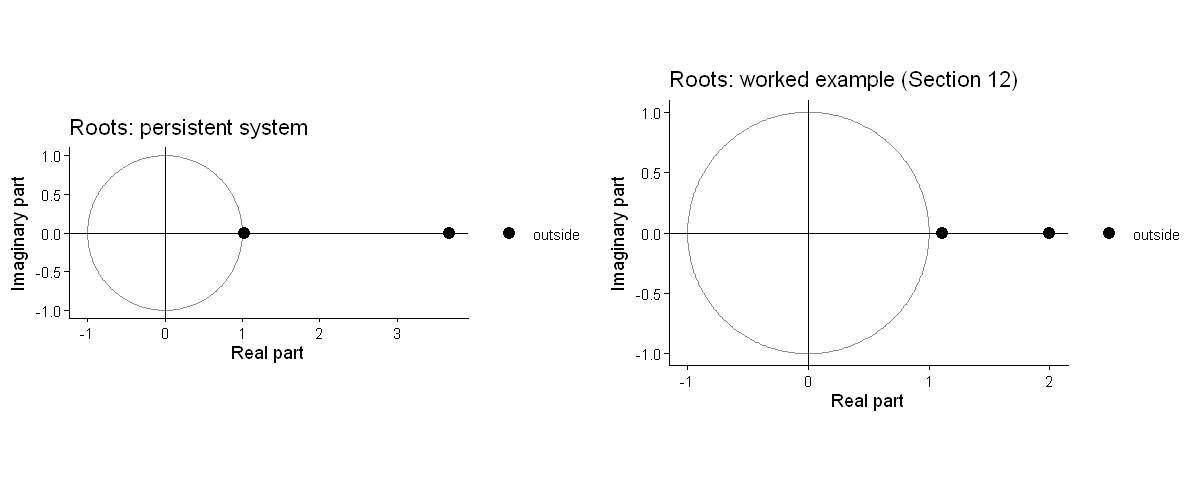

In [4]:
# Stability of the two first-order examples: eigenvalues of A1 and roots of det(I - A1 z)
examples <- list(
  `Persistent system`        = matrix(c(0.625, 0.5,  0.25, 0.625), 2, 2, byrow = TRUE),
  `Worked example (Sec. 12)` = matrix(c(0.7,   0.2,  0.2,  0.7  ), 2, 2, byrow = TRUE))
z_roots <- list()
for (nm in names(examples)) {
  A  <- examples[[nm]]
  ev <- eigen(A)$values
  z  <- polyroot(c(1, -sum(diag(A)), det(A)))     # 2 x 2: det(I - A z) = 1 - tr(A) z + det(A) z^2
  z_roots[[nm]] <- z
  cat(sprintf("%-25s eigenvalues: %s    roots z: %s    1/roots: %s    half-life: %.1f periods\n",
              nm, paste(sprintf("%.3f", ev), collapse = ", "),
              paste(sprintf("%.3f", sort(Re(z))), collapse = ", "),
              paste(sprintf("%.3f", sort(1 / Re(z), decreasing = TRUE)), collapse = ", "),
              log(0.5) / log(max(Mod(ev)))))
}
options(repr.plot.height = 4)
grid.arrange(roots_plot(z_roots[[1]], title = "Roots: persistent system"),
             roots_plot(z_roots[[2]], title = "Roots: worked example (Section 12)"), ncol = 2)
options(repr.plot.height = 6)

**Reading the output.** The eigenvalues and roots confirm the algebra: $0.979$ and $0.271$ (roots $1.022$ and $3.684$) for the persistent system, and $0.9$ and $0.5$ (roots $1.111$ and $2$) for the worked example. In both cases the reciprocals of the roots are the eigenvalues, and both pairs of roots lie outside the unit circle (black). The half-life of the slowest component is $\ln0.5/\ln\lambda_{\max}$: 32 periods for the persistent system, whose root sits just outside the circle, against 6.6 periods for the worked example. After 20 periods a shock to the persistent system has lost only about a third of its slow component ($0.979^{20}\approx0.65$), while one to the worked example has lost about 90% ($0.9^{20}\approx0.12$).

# 5&nbsp;&nbsp;The vector moving-average (Wold) representation

## From the VAR to the VMA

Let $A(L)=I-A_1L-\cdots-A_pL^p$ be the lag polynomial of the reduced form, so that $A(L)X_t=A_0+e_t$. If the VAR is stable, $A(L)^{-1}$ exists as a convergent power series, and

$$
X_t=\mu+\sum_{j=0}^{\infty}\Phi_je_{t-j},
\qquad
\mu=A(1)^{-1}A_0=(I-A_1-\cdots-A_p)^{-1}A_0,
\qquad
\Phi_0=I,
\qquad
\Phi_j\to0\ \ (j\to\infty).
$$

This is the **vector moving-average (VMA)** or multivariate **Wold representation** (Wold 1938; Lectures 6–8 for the univariate case): every stationary VAR is a VMA($\infty$) in its own one-step-ahead forecast errors $e_t$.

**First order.** For $X_t=A_0+A_1X_{t-1}+e_t$,

$$
(I-A_1L)^{-1}=I+A_1L+A_1^2L^2+\cdots=\sum_{j=0}^{\infty}A_1^{\,j}L^j ,
$$

so

$$
X_t=(I-A_1)^{-1}A_0+\sum_{j=0}^{\infty}A_1^{\,j}e_{t-j}
=\overline X+\sum_{j=0}^{\infty}A_1^{\,j}e_{t-j},
\qquad \Phi_j=A_1^{\,j},
$$

with $\overline X=(I-A_1)^{-1}A_0$, which exists whenever $I-A_1$ is nonsingular. In components,

$$
\begin{bmatrix}Y_t\\Z_t\end{bmatrix}
=
\begin{bmatrix}\overline Y\\\overline Z\end{bmatrix}
+
\sum_{j=0}^{\infty}
\begin{bmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{bmatrix}^{j}
\begin{bmatrix}e_{1,t-j}\\e_{2,t-j}\end{bmatrix}.
$$

**Order $p$.** Matching powers of $L$ in $A(L)\Phi(L)=I$ gives the recursion that `vma()` implements (matching powers in $\Phi(L)A(L)=I$ gives the equivalent $\Phi_j=\sum_i\Phi_{j-i}A_i$):

$$
\Phi_0=I,\qquad \Phi_j=\sum_{i=1}^{\min(j,p)}A_i\Phi_{j-i}\quad(j\ge1).
$$

## What the VMA delivers

- **The mean:** $E(X_t)=\mu$.
- **The variance:** $\operatorname{Var}(X_t)=\sum_{j=0}^{\infty}\Phi_j\Sigma_e\Phi_j'$. For a VAR(1) it also solves $\operatorname{Var}(X_t)=A_1\operatorname{Var}(X_t)A_1'+\Sigma_e$.
- **Forecast errors:** the $n$-step-ahead forecast error is $X_{t+n}-E_tX_{t+n}=\sum_{j=0}^{n-1}\Phi_je_{t+n-j}$ — the basis of forecast intervals (Section 7) and of the variance decomposition (Section 11).

## Forecast-error impulse responses

The VMA is also the basis of **impulse response analysis**. The elements of $\Phi_h$ are the **forecast-error impulse responses**:

$$
\phi_{ij,h}=\frac{\partial X_{i,t+h}}{\partial e_{jt}},
$$

the response of variable $i$, $h$ periods later, to a one-unit **reduced-form** innovation in equation $j$ at time $t$. In the bivariate case, for example, $\phi_{11,1}=\partial Y_{t+1}/\partial e_{1t}$ and $\phi_{12,1}=\partial Y_{t+1}/\partial e_{2t}$. They are called forecast-error responses because $e_t$ is the one-step-ahead forecast error, and they need no identifying assumption: `vars::Phi()` computes them from the estimated $\hat A_i$.

They are of limited economic use, for two reasons.

1. **$\Phi_0=I$.** A unit $e_{1t}$ moves only $Y_t$ on impact, with $e_{2t}$ held at zero. But $e_{1t}$ and $e_{2t}$ are correlated (Section 3), so in the data an innovation in one equation typically comes with an innovation in the other. The experiment "$e_1$ moves, $e_2$ does not" is not representative.
2. **No economic label.** Each $e_{jt}$ is a mixture of the structural shocks, so a response to $e_{1t}$ is not the response to any economically meaningful disturbance.

Economically meaningful responses are responses to the **structural** shocks. Substituting $e_t=B^{-1}\varepsilon_t=Pu_t$ into the VMA gives them, $\Psi_h=\Phi_hB^{-1}$ and $\Theta_h=\Phi_hP$ (Section 11) — but computing either requires $B$ (or $P$), which the reduced form does not reveal. Recovering it is the identification problem of Part II.

# 6&nbsp;&nbsp;Estimation, lag length and diagnostics

## Estimation

Write the VAR($p$) as a system in which every equation has the same regressors, $W_{t-1}=(1,X_{t-1}',\dots,X_{t-p}')'$.

- **OLS equation by equation is consistent and efficient.** The regressors are predetermined, and because every equation has the same regressors, seemingly unrelated regressions (SUR/GLS) collapse to OLS (Zellner 1962). Under Gaussian errors OLS is also the conditional maximum likelihood estimator.
- **Residual covariance.** $\Sigma_e$ is estimated by $\hat\Sigma_e=T^{-1}\sum_t\hat e_t\hat e_t'$, often with a degrees-of-freedom correction; `summary()` of a **vars** fit (element `covres`) divides by $T$ minus the number of coefficients in each equation.
- **Parameter count.** A $k$-variable VAR($p$) with intercepts has $k+pk^2$ mean parameters plus $k(k+1)/2$ distinct elements of $\Sigma_e$; deterministic seasonal or trend terms add more. The count grows quickly with $k$ and $p$ — the "curse of dimensionality" that motivates parsimony and, for larger systems, Bayesian shrinkage.
- **Over-parameterization is expected.** Many individual coefficients will be insignificant. They have no structural interpretation and are not meant to be read one by one: the reduced form's job is to summarize the dynamics and deliver $\hat\Sigma_e$. Its joint implications — forecasts, impulse responses and variance decompositions — are the objects of interest.
- **Variable selection** should be guided by economic theory and data availability. A relevant variable left out of the system ends up in the residuals, which can then be correlated with the regressors and with each other.

## Determining the lag length

Let the unrestricted VAR have $p_u$ lags and the restricted VAR $p_r<p_u$ lags, both estimated **on the same sample** of $T$ usable observations, with residual covariance matrices $\hat\Sigma_u$ and $\hat\Sigma_r$.

**Likelihood ratio test.** Following Sims (1980) and Enders (2015, Ch. 5),

$$
LR=(T-c)\big(\ln|\hat\Sigma_r|-\ln|\hat\Sigma_u|\big)\;\overset{a}{\sim}\;\chi^2(q),
$$

where $q=k^2(p_u-p_r)$ is the number of restrictions ($k^2$ coefficients per lag) and $c$ is the number of parameters estimated in **each equation** of the unrestricted system, $c=1+kp_u$ with an intercept. The factor $T-c$ instead of $T$ is Sims's small-sample correction, which makes the test less likely to reject. Reject the shorter lag length if $LR$ exceeds the $\chi^2(q)$ critical value.

**Information criteria.** The multivariate versions are

$$
AIC=T\ln|\hat\Sigma|+2N,\qquad SBC\ (=BIC)=T\ln|\hat\Sigma|+N\ln T,
$$

where $N$ is the total number of mean parameters in all equations, $N=k^2p+k$ with intercepts (plus any other deterministic terms). `vars::VARselect()` reports the per-observation versions, computed on a common sample for every lag order:

$$
\ln|\hat\Sigma|+\frac{2N}{T}\ (\text{AIC}),\qquad
\ln|\hat\Sigma|+\frac{2N\ln\ln T}{T}\ (\text{HQ}),\qquad
\ln|\hat\Sigma|+\frac{N\ln T}{T}\ (\text{SC}).
$$

Choose the lag length that **minimizes** the criterion. As in the univariate case, AIC tends to choose longer lags; SC (= SBC = BIC) is consistent and parsimonious; HQ lies in between. Adding lags will not fix an omitted-variable problem.

## Diagnostics

After estimation, check that the model is adequate.

1. **Stability.** All companion eigenvalues must lie inside the unit circle (Section 4): `roots()`.
2. **No residual autocorrelation.** Test the residuals with the multivariate portmanteau (Ljung–Box) test and the Breusch–Godfrey LM test, the system counterparts of the tests of Lecture 9: `serial.test()`. If they reject, add lags or reconsider the variables.
3. **Normality and conditional heteroskedasticity:** `normality.test()` and `arch.test()`. Macroeconomic residuals frequently reject both, especially across the 1970s and the Great Moderation. This does not invalidate OLS, but it matters for inference, and heteroskedasticity can itself be exploited for identification (LN17).

If the diagnostics fail, revisit the variables, the lag length and the deterministic terms (for example, dummies for breaks).

# 7&nbsp;&nbsp;Granger causality and forecasting

## Granger causality and block exogeneity

$Z$ does **not Granger-cause** $Y$ if lagged values of $Z$ do not help to predict $Y$ once lagged $Y$ has been accounted for (Granger 1969). In the $Y$ equation of a VAR($p$) this is

$$
H_0:\ a_{12,1}=a_{12,2}=\cdots=a_{12,p}=0,
$$

where $a_{12,i}$ is the $(1,2)$ element of $A_i$: a Wald or $F$ test of $p$ restrictions. The **block-exogeneity** test generalizes this to groups of variables — do the lags of $Z_1,\dots,Z_m$ jointly help to predict $Y$? — with an LR test of the restricted against the unrestricted system.

Three cautions.

- Granger causality concerns **predictability**, not causation in the structural sense. Recall from Section 2 that $a_{21}=(c_{21}-b_{21}c_{11})/(1-b_{12}b_{21})$: lagged $Y$ can predict $Z$ even when $Y_{t-1}$ has no direct effect on $Z_t$ ($c_{21}=0$), because $Y_{t-1}$ moves $Y_t$ and $Y_t$ moves $Z_t$ within the period.
- It says nothing about **contemporaneous** effects. These show up in the residual covariance $\sigma_{12}$. `vars::causality()` also reports a test of **instantaneous causality**, $H_0:\sigma_{12}=0$; when it rejects, the reduced-form errors are correlated and the identification problem of Part II has real consequences.
- The answer depends on the information set: adding a third variable can make a Granger-causal relation disappear, or create one.

## Forecasting

The minimum-MSE $h$-step forecast iterates the estimated VAR forward, replacing future errors by their expected value of zero:

$$
\hat X_{T+h|T}=\hat A_0+\hat A_1\hat X_{T+h-1|T}+\cdots+\hat A_p\hat X_{T+h-p|T},\qquad \hat X_{T+j|T}=X_{T+j}\ \text{for } j\le0 .
$$

From the VMA (Section 5), the forecast error and its mean squared error are

$$
X_{T+h}-\hat X_{T+h|T}=\sum_{i=0}^{h-1}\Phi_ie_{T+h-i},\qquad
\Sigma(h)=\sum_{i=0}^{h-1}\Phi_i\Sigma_e\Phi_i' .
$$

As $h$ grows the forecasts converge to the mean $\mu$ and $\Sigma(h)$ converges to the unconditional variance $\operatorname{Var}(X_t)$. The diagonal of $\Sigma(h)$ gives Gaussian prediction intervals, $\hat X_{i,T+h|T}\pm1.96\sqrt{\Sigma_{ii}(h)}$ (ignoring parameter uncertainty). Splitting $\Sigma(h)$ by structural shock is the variance decomposition of Section 11 — possible only once the shocks have been identified.

# 8&nbsp;&nbsp;Application I: a reduced-form VAR for industrial production growth and inflation

We use **quarterly** US data in `varQ11.csv` (Enders 2015, Ch. 5, Question 11), with both variables defined as log changes:

$$
DIIP_t\equiv\ln IIP_t-\ln IIP_{t-1},\qquad INF_t\equiv\ln CPI_t-\ln CPI_{t-1}.
$$

The file has a date column followed by `DIIP` and `INF`; the series start in 1960Q2, the first quarter for which a difference is available. The steps follow Sections 4–7: pre-test the variables, choose the lag length, estimate, check the diagnostics, then test Granger causality and forecast. The objects created here (`data1`, `p_sel`, `varest`) are used again in Application II (Section 14). The commentary quotes the results obtained with the course data.

In [5]:
# Application data: quarterly US industrial production growth and CPI inflation, in log changes
mydata <- read.csv("../data/varQ11.csv", header = TRUE)
data1  <- ts(mydata[, c("DIIP", "INF")], frequency = 4, start = c(1960, 2))   # select columns by name
cat("Sample:", paste(start(data1), collapse = "Q"), "to", paste(end(data1), collapse = "Q"),
    "   T =", nrow(data1), "quarters\n")
head(data1)

Sample: 1960Q2 to 2012Q4    T = 211 quarters


,DIIP,INF
1960 Q2,-0.02196962,0.002503994
1960 Q3,-0.01679988,0.000293641
1960 Q4,-0.02418232,0.002779728
1961 Q1,-0.01524693,0.000874125
1961 Q2,0.03856006,-0.000145565
1961 Q3,0.03166717,0.001743573


## 8.1 Pre-testing the variables

A VAR in the levels of its variables needs each series to be $I(0)$, both for the usual asymptotics and for a valid Wold representation (Section 5). Start with a plot.

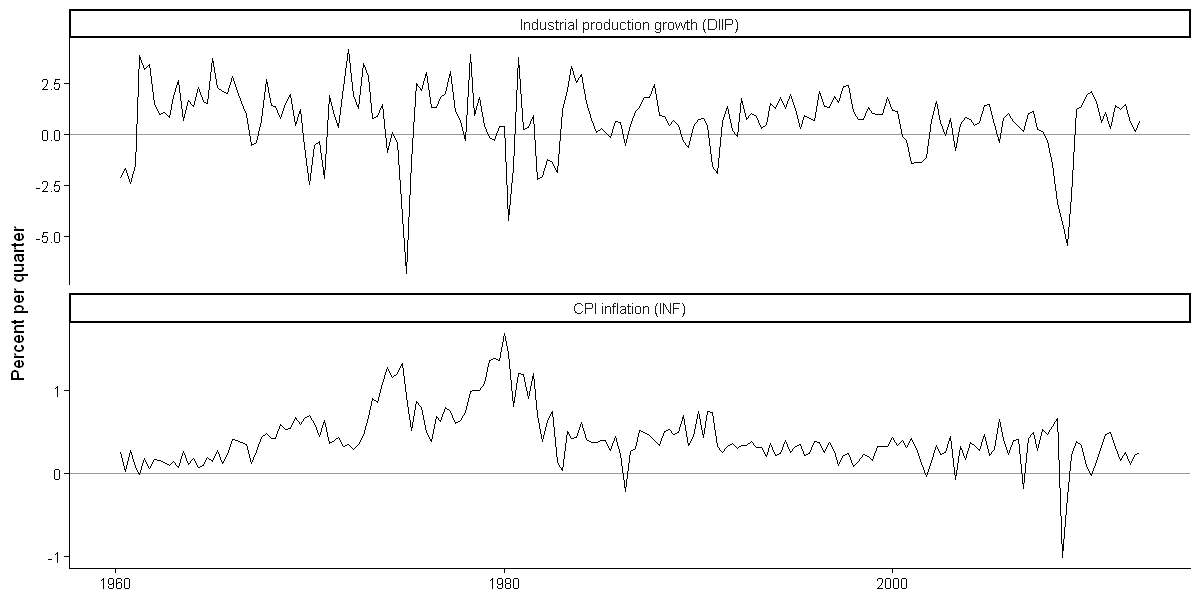

In [6]:
labs_ts <- c(DIIP = "Industrial production growth (DIIP)", INF = "CPI inflation (INF)")
ts_df <- data.frame(date   = rep(as.numeric(time(data1)), 2),
                    series = factor(rep(labs_ts, each = nrow(data1)), levels = labs_ts),
                    value  = 100 * c(data1[, "DIIP"], data1[, "INF"]))
options(repr.plot.height = 5)
print(ggplot(ts_df, aes(date, value)) + theme_classic() +
  geom_hline(yintercept = 0, colour = "grey60") + geom_line() +
  facet_wrap(~ series, ncol = 1, scales = "free_y") +
  labs(x = NULL, y = "Percent per quarter"))
options(repr.plot.height = 6)

We test each series for a unit root with the **augmented Dickey–Fuller** test with a drift (Lecture 10),

$$
\Delta x_t=a_0+\gamma\,x_{t-1}+\sum_{i=1}^{n}\beta_i\,\Delta x_{t-i}+\varepsilon_t ,\qquad H_0:\gamma=0\ \text{(unit root)},
$$

with the number of lagged differences $n\le8$ chosen by AIC so that the residuals are free of serial correlation.

In [7]:
adf_diip <- ur.df(data1[, "DIIP"], type = "drift", lags = 8, selectlags = "AIC")
adf_inf  <- ur.df(data1[, "INF"],  type = "drift", lags = 8, selectlags = "AIC")

adf_tab <- data.frame(
  tau_mu = c(adf_diip@teststat[1, "tau2"], adf_inf@teststat[1, "tau2"]),
  cv_5pc = c(adf_diip@cval["tau2", "5pct"], adf_inf@cval["tau2", "5pct"]),
  row.names = c("DIIP", "INF"))
round(adf_tab, 3)

,tau_mu,cv_5pc
,<dbl>,<dbl>
DIIP,-6.161,-2.88
INF,-2.982,-2.88


**Reading the output.** With the course data, $\tau_\mu=-6.16$ for DIIP and $-2.98$ for INF, against a 5% critical value of $-2.88$. We reject a unit root in both series at 5%:

$$
DIIP_t\sim I(0),\qquad INF_t\sim I(0).
$$

The rejection for INF is marginal. Inflation is very persistent in post-war US data, and many applied papers treat it as close to a unit root, so keep this in mind when reading long-horizon results.

## 8.2 Lag selection

### Predict

Per parameter, AIC charges $2/T$ and SC charges $\ln T/T$. With about 200 quarterly observations, which penalty is larger, and which criterion will therefore choose the longer lag?

In [8]:
infocrit <- VARselect(data1, lag.max = 8, type = "const")
round(t(infocrit$criteria[c("AIC(n)", "HQ(n)", "SC(n)"), ]), 3)
infocrit$selection

,AIC(n),HQ(n),SC(n)
1,-21.070,-21.030,-20.972
2,-21.107,-21.041,-20.943
3,-21.208,-21.116,-20.980
4,-21.214,-21.095,-20.920
5,-21.218,-21.072,-20.858
6,-21.196,-21.024,-20.771
7,-21.173,-20.974,-20.683
8,-21.153,-20.929,-20.598


AIC(n)  HQ(n)  SC(n) FPE(n) 
     5      3      3      5

**Reading the output.** With the course data:

- **AIC** is minimized at 5 lags ($-21.218$);
- **HQ** ($-21.116$) and **SC** ($-20.980$) are both minimized at **3 lags**.

As predicted, AIC — whose penalty per parameter, $2/T$, is smaller than SC's $\ln T/T\approx5.3/T$ — chooses the longer lag. We follow SC and HQ and use $p=3$. The choice is provisional: if the residuals of the VAR(3) were serially correlated, we would add lags.

## 8.3 Estimation and diagnostics

With $X_t=(DIIP_t,INF_t)'$ the VAR(3) is

$$
X_t=A_0+A_1X_{t-1}+A_2X_{t-2}+A_3X_{t-3}+e_t .
$$

We pass the selected lag order explicitly (`p = p_sel`) rather than `ic = "SC"`. If `VAR()` chose the lag order itself, every bootstrap replication in Application II would re-select it, and the bootstrap draws would come from models with different lag orders.

In [9]:
p_sel  <- infocrit$selection[["SC(n)"]]     # = 3 for the course data
varest <- VAR(data1, p = p_sel, type = "const")

# Coefficients and p-values, equation by equation
coef_tab <- do.call(rbind, lapply(names(coef(varest)), function(eq) {
  cf <- coef(varest)[[eq]]
  data.frame(Equation = eq, Regressor = rownames(cf),
             Coef = round(cf[, "Estimate"], 3), p.value = round(cf[, "Pr(>|t|)"], 3),
             row.names = NULL)
}))
coef_tab

Equation,Regressor,Coef,p.value
<chr>,<chr>,<dbl>,<dbl>
DIIP,DIIP.l1,0.632,0.000
DIIP,INF.l1,-0.525,0.203
DIIP,DIIP.l2,-0.181,0.030
DIIP,INF.l2,0.182,0.702
DIIP,DIIP.l3,0.073,0.286
DIIP,INF.l3,-0.732,0.080
DIIP,const,0.008,0.000
INF,DIIP.l1,0.042,0.000
INF,INF.l1,0.560,0.000


Several individual coefficients are insignificant. As Section 6 noted, this is normal for a reduced-form VAR and carries no structural meaning. Next, the diagnostics of Section 6.

In [10]:
# 1. Stability: moduli of the companion-matrix eigenvalues (all must be below one)
round(roots(varest), 4)

# 2-3. Residual autocorrelation, normality and ARCH effects
tests <- list(`Portmanteau, 12 lags`            = serial.test(varest, lags.pt = 12, type = "PT.asymptotic")$serial,
              `Breusch-Godfrey LM, 4 lags`      = serial.test(varest, lags.bg = 4,  type = "BG")$serial,
              `Jarque-Bera, multivariate`       = normality.test(varest)$jb.mul$JB,
              `ARCH-LM, multivariate, 4 lags`   = arch.test(varest, lags.multi = 4)$arch.mul)
data.frame(statistic = sapply(tests, function(h) round(unname(h$statistic), 2)),
           df        = sapply(tests, function(h) paste(h$parameter, collapse = ", ")),
           p.value   = sapply(tests, function(h) signif(h$p.value, 3)))

[1] 0.8835 0.6223 0.6067 0.6067 0.3988 0.3988

,statistic,df,p.value
,<dbl>,<chr>,<dbl>
"Portmanteau, 12 lags",46.81,36,1.07e-01
"Breusch-Godfrey LM, 4 lags",27.08,16,4.06e-02
"Jarque-Bera, multivariate",1355.39,4,0.00e+00
"ARCH-LM, multivariate, 4 lags",127.82,36,3.31e-12


**Reading the output.** With the course data, the largest companion eigenvalue modulus is 0.884, so the VAR is **stable** and has a valid Wold representation; the slowest component of a shock shrinks by about 12% a quarter. The portmanteau test with 12 lags gives $\chi^2(36)=46.8$ ($p=0.107$), so we do not reject the null of no residual autocorrelation at 5%; check that the Breusch–Godfrey test agrees. If the normality and ARCH tests reject, that is typical of macroeconomic residuals (Section 6): it does not invalidate OLS, but it is a reason to prefer bootstrap bands over asymptotic ones in Application II.

## 8.4 Granger causality

`causality()` tests the Granger null of Section 7 for one variable at a time, together with instantaneous causality.

In [11]:
gc_tab <- do.call(rbind, lapply(c("INF", "DIIP"), function(cause) {
  ca <- causality(varest, cause = cause)
  data.frame(H0 = c(ca$Granger$method, ca$Instant$method),
             statistic = round(c(ca$Granger$statistic, ca$Instant$statistic), 3),
             p.value   = signif(c(ca$Granger$p.value, ca$Instant$p.value), 3),
             row.names = NULL)
}))
gc_tab

H0,statistic,p.value
<chr>,<dbl>,<dbl>
Granger causality H0: INF do not Granger-cause DIIP,4.819,0.00262
H0: No instantaneous causality between: INF and DIIP,3.455,0.06310
Granger causality H0: DIIP do not Granger-cause INF,5.105,0.00178
H0: No instantaneous causality between: DIIP and INF,3.455,0.06310


**Reading the output.** The first and third rows are Granger tests: does inflation help to predict industrial production growth, given past growth, and vice versa? Each is an $F$ test of $p=3$ zero restrictions. A small $p$-value says that the lags of the "cause" variable improve the forecasts of the other — a statement about predictability, not about structural causation (Section 7).

The second and fourth rows test instantaneous causality. They are the same test, $H_0:\sigma_{12}=0$, and so report the same result. Its outcome tells us how much is at stake in Application II: if the residuals are only weakly correlated, the choice of ordering matters little.

## 8.5 Forecast-error impulse responses

`Phi()` returns the reduced-form VMA matrices $\hat\Phi_0=I,\hat\Phi_1,\hat\Phi_2,\ldots$ of Section 5. Element $[i,j]$ of $\hat\Phi_h$ is the response of variable $i$ at horizon $h$ to a unit reduced-form innovation $e_{jt}$.

In [12]:
round(Phi(varest, nstep = 3), 3)
# Phi_1 = A_1, as the VMA recursion requires
all.equal(Phi(varest, nstep = 1)[, , 2], Acoef(varest)[[1]], check.attributes = FALSE)

, , 1

     [,1] [,2]
[1,]    1    0
[2,]    0    1

, , 2

      [,1]   [,2]
[1,] 0.632 -0.525
[2,] 0.042  0.560

, , 3

      [,1]   [,2]
[1,] 0.196 -0.444
[2,] 0.026  0.307

, , 4

      [,1]   [,2]
[1,] 0.076 -0.977
[2,] 0.021  0.496

[1] TRUE

**Reading the output.** With the course data

$$
\hat\Phi_1=\begin{bmatrix}0.63&-0.53\\0.04&0.56\end{bmatrix}.
$$

For example, $\phi_{11,1}=0.63$: a unit innovation in the DIIP equation at $t$ raises DIIP at $t+1$ by 0.63. And $\hat\Phi_1=\hat A_1$, as the recursion of Section 5 requires.

The impact matrix $\Phi_0=I$ says that $e_{1t}$ moves only DIIP on impact. That is an artefact of the reduced form, not an economic statement (Section 5) — one of the two reasons to go on to Part II.

## 8.6 Forecasts

`predict()` iterates the VAR forward as in Section 7. The plot shows the last ten years of data, the forecasts for the next eight quarters with 95% intervals, and the model mean $\hat\mu=\hat A(1)^{-1}\hat A_0$ (Section 5).

,model_mean,sample_mean
DIIP,0.00713,0.00668
INF,0.00433,0.00425


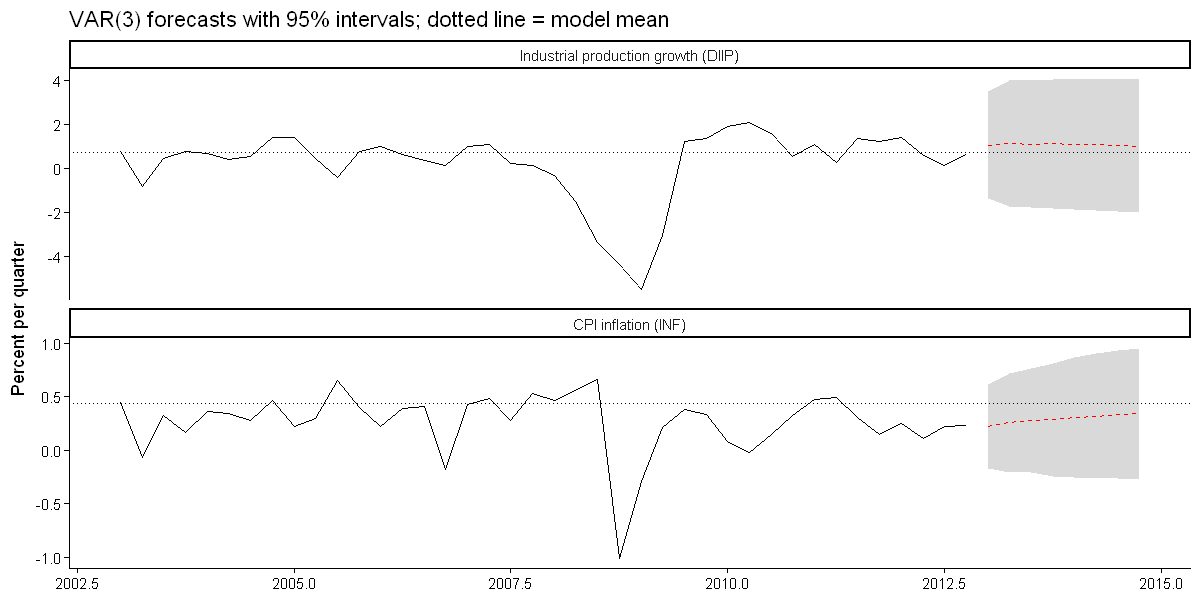

In [13]:
h_fc <- 8
fc   <- predict(varest, n.ahead = h_fc, ci = 0.95)
mu_hat <- solve(diag(2) - Reduce(`+`, Acoef(varest)), Bcoef(varest)[, "const"])   # A(1)^{-1} A_0
names(mu_hat) <- colnames(data1)

tt     <- as.numeric(time(data1))
fc_df  <- do.call(rbind, lapply(c("DIIP", "INF"), function(v)
  data.frame(series = factor(unname(labs_ts[v]), levels = labs_ts), date = tail(tt, 1) + (1:h_fc) / 4,
             fcst  = 100 * fc$fcst[[v]][, "fcst"],
             lower = 100 * fc$fcst[[v]][, "lower"], upper = 100 * fc$fcst[[v]][, "upper"])))
mean_df <- data.frame(series = factor(labs_ts, levels = labs_ts), mean = 100 * mu_hat)
round(cbind(model_mean = mu_hat, sample_mean = colMeans(data1)), 5)

options(repr.plot.height = 5)
print(ggplot() + theme_classic() +
  geom_ribbon(data = fc_df, aes(date, ymin = lower, ymax = upper), fill = "grey85") +
  geom_hline(data = mean_df, aes(yintercept = mean), linetype = "dotted") +
  geom_line(data = subset(ts_df, date > tail(tt, 1) - 10), aes(date, value)) +
  geom_line(data = fc_df, aes(date, fcst), colour = "red", linetype = "dashed") +
  facet_wrap(~ series, ncol = 1, scales = "free_y") +
  labs(x = NULL, y = "Percent per quarter",
       title = paste0("VAR(", p_sel, ") forecasts with 95% intervals; dotted line = model mean")))
options(repr.plot.height = 6)

**Reading the output.** The forecasts revert towards the model mean $\hat\mu$, which is close to the sample mean, and the intervals widen towards the unconditional spread of each series, as Section 7 predicts. How fast this happens is governed by the companion eigenvalues: the slowest component shrinks by the factor 0.884 a quarter, so roughly a third of a deviation from the mean ($0.884^8\approx0.37$) is still present after two years.

Part I ends here. Everything so far — the coefficients, the diagnostics, the Granger tests, the forecasts and $\hat\Phi_h$ — required no assumption about the contemporaneous structure. Part II asks what it takes to go further.

# Part II&nbsp;&nbsp;Identification and innovation accounting

The reduced form summarizes the data, but its errors are correlated mixtures of the structural shocks, so it cannot say how the variables respond to an economically meaningful disturbance. Part II shows why the structure cannot be recovered without restrictions (Section 9), how a recursive ordering identifies it (Section 10), how the identified model is described by impulse responses and variance and historical decompositions (Section 11), works through a complete example by hand (Section 12), and looks beyond recursive orderings (Section 13). Application II (Section 14) identifies the VAR of Application I.

# 9&nbsp;&nbsp;The identification problem

## Why the reduced form is not enough

The reduced form can be estimated consistently by OLS because its right-hand side contains only predetermined variables and its errors are white noise — serially uncorrelated, though correlated across equations. The structural form cannot, because its contemporaneous terms are correlated with the structural shocks (Section 2). Our goal is to **recover the primitive system** — the contemporaneous relations in $B$ and the orthogonal shocks $\varepsilon_t$ — from the reduced-form estimates. **Identification** is precisely this inverse problem: from $\hat A_0,\hat A_1,\dots,\hat A_p$ and $\hat\Sigma_e$, can we uniquely recover $(B,D,\Gamma_0,\dots,\Gamma_p)$ and the structural shocks? Sims (1980) emphasized that without **restrictions** on the primitive system the answer is no.

## Counting parameters

In the bivariate VAR(1) (Enders 2015, Ch. 5):

| | Reduced form | Structural form |
|---|---|---|
| Intercepts | $a_{10},a_{20}$: 2 | $b_{10},b_{20}$: 2 |
| Lag coefficients | $a_{11},a_{12},a_{21},a_{22}$: 4 | $c_{11},c_{12},c_{21},c_{22}$: 4 |
| Contemporaneous coefficients | — | $b_{12},b_{21}$: 2 |
| Shock (co)variances | $\sigma_1^2,\sigma_2^2,\sigma_{12}$: 3 | $\sigma_{\varepsilon y}^2,\sigma_{\varepsilon z}^2$: 2 |
| **Total** | **9** | **10** |

The structural model is **under-identified by one parameter**: at least one restriction is needed. Given $B$, everything else follows at once ($\Gamma_i=BA_i$), so the whole problem lies in the link between $\Sigma_e$ and $(B,D)$:

$$
\Sigma_e=B^{-1}DB^{-1\prime}
\quad\Longleftrightarrow\quad
D=B\,\Sigma_e\,B' ,
$$

that is,

$$
\begin{bmatrix}\sigma_1^2&\sigma_{12}\\\sigma_{12}&\sigma_2^2\end{bmatrix}
=
\frac{1}{\Delta}\begin{bmatrix}1&-b_{12}\\-b_{21}&1\end{bmatrix}
\begin{bmatrix}\sigma_{\varepsilon y}^2&0\\0&\sigma_{\varepsilon z}^2\end{bmatrix}
\frac{1}{\Delta}\begin{bmatrix}1&-b_{21}\\-b_{12}&1\end{bmatrix},
\qquad \Delta=1-b_{12}b_{21}:
$$

three distinct elements on the left, four unknowns on the right.

## In general

With $k$ variables, $\Sigma_e$ is symmetric and has $k(k+1)/2$ distinct elements. The unknowns are the $k(k-1)$ off-diagonal elements of $B$ (its diagonal is normalized to one) and the $k$ variances in $D$: $k^2$ in all. We are short of

$$
k^2-\frac{k(k+1)}{2}=\frac{k(k-1)}{2}
$$

restrictions — the number of elements in one triangle of $B$: 1 when $k=2$, 3 when $k=3$, 10 when $k=5$. This is the **order condition**. It is necessary but not sufficient: the restrictions must also satisfy a **rank condition** (Section 13).

## The same problem as a rotation

Write $P=B^{-1}D^{1/2}$, so that $\Sigma_e=PP'$. If $P$ satisfies this equation, so does $PQ$ for **any** orthogonal matrix $Q$, because $PQ(PQ)'=PQQ'P'=PP'$. Each $Q$ defines a different set of structural shocks, $u_t=(PQ)^{-1}e_t$, with different impulse responses, and every one of them fits the data equally well. The data cannot distinguish between these candidate structures; **identification means choosing among them with economic information.**

| Strategy | Information used | Where |
|---|---|---|
| Recursive (Cholesky) zero restrictions on impact | timing of within-period responses | Sections 10, 12 and 14 |
| Non-recursive zeros and calibrated coefficients | economic theory, outside estimates | Sections 13 and 14.8 |
| Long-run zero restrictions | which shocks have permanent effects | LN15 |
| Sign, narrative and max-share restrictions | qualitative theory, historical events | LN16 |
| External instruments and local projections | outside measures of the shock | LN17 |

In every case, once $B$ (or $P$) is pinned down, the structural shocks are $\hat\varepsilon_t=\hat B\hat e_t$ (or $\hat u_t=\hat P^{-1}\hat e_t$), and the structural impulse responses are $\hat\Psi_h=\hat\Phi_h\hat B^{-1}$ (or $\hat\Theta_h=\hat\Phi_h\hat P$).

# 10&nbsp;&nbsp;Recursive identification and the Cholesky factorization

## A recursive ordering

The most common restriction is a **recursive ordering** (Sims 1980): variables earlier in the ordering may affect later ones within the period, but not vice versa. In the bivariate model, suppose $Y_t$ may respond contemporaneously to $Z_t$ but $Z_t$ does **not** respond contemporaneously to $Y_t$: $b_{21}=0$, and $Z$ is ordered first. The primitive system becomes

$$
\begin{aligned}
Y_t &= b_{10}-b_{12}Z_t+c_{11}Y_{t-1}+c_{12}Z_{t-1}+\varepsilon_{yt},\\
Z_t &= b_{20}\phantom{{}-b_{12}Z_t}+c_{21}Y_{t-1}+c_{22}Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad
B=\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix},
\qquad
B^{-1}=\begin{bmatrix}1&-b_{12}\\0&1\end{bmatrix}.
$$

Premultiplying by $B^{-1}$ and matching coefficients with the reduced form gives

$$
\begin{aligned}
a_{10}&=b_{10}-b_{12}b_{20}, & a_{20}&=b_{20},\\
a_{11}&=c_{11}-b_{12}c_{21}, & a_{21}&=c_{21},\\
a_{12}&=c_{12}-b_{12}c_{22}, & a_{22}&=c_{22},\\
e_{1t}&=\varepsilon_{yt}-b_{12}\varepsilon_{zt}, & e_{2t}&=\varepsilon_{zt}.
\end{aligned}
$$

The variable ordered first ($Z$) has a reduced-form error equal to its own structural shock; the second variable's error mixes both shocks. The reduced-form covariance matrix becomes

$$
\sigma_1^2=\sigma_{\varepsilon y}^2+b_{12}^2\sigma_{\varepsilon z}^2,\qquad
\sigma_2^2=\sigma_{\varepsilon z}^2,\qquad
\sigma_{12}=-b_{12}\sigma_{\varepsilon z}^2 :
$$

three equations in three unknowns, with the unique solution

$$
\sigma_{\varepsilon z}^2=\sigma_2^2,\qquad
b_{12}=-\frac{\sigma_{12}}{\sigma_2^2},\qquad
\sigma_{\varepsilon y}^2=\sigma_1^2-\frac{\sigma_{12}^2}{\sigma_2^2}.
$$

The model is now **exactly identified**: the structural parameters follow from the reduced form — $b_{20}=a_{20}$, $c_{21}=a_{21}$, $c_{22}=a_{22}$, $b_{10}=a_{10}+b_{12}a_{20}$, $c_{11}=a_{11}+b_{12}a_{21}$, $c_{12}=a_{12}+b_{12}a_{22}$ — and so do the structural shocks, $\varepsilon_{zt}=e_{2t}$ and $\varepsilon_{yt}=e_{1t}+b_{12}e_{2t}$. An equivalent and often convenient route is $D=B\Sigma_eB'$: choose $b_{12}$ so that $B\Sigma_eB'$ is diagonal (Section 12, Step 4).

## The Cholesky factorization does it in one step

Write $D=D^{1/2}D^{1/2}$ with $D^{1/2}=\operatorname{diag}(\sigma_{\varepsilon y},\sigma_{\varepsilon z})$. Then

$$
\Sigma_e=B^{-1}DB^{-1\prime}
=\big(B^{-1}D^{1/2}\big)\big(B^{-1}D^{1/2}\big)'
=PP',
\qquad P\equiv B^{-1}D^{1/2}.
$$

Under a recursive ordering $B^{-1}$ is triangular with ones on the diagonal, so $P$ is triangular with the structural standard deviations on its diagonal. A symmetric positive definite matrix has exactly one factorization $PP'$ with $P$ lower triangular and a positive diagonal — its **Cholesky factorization**. So, once the variables are listed in the chosen order, **computing the Cholesky factor of $\Sigma_e$ is the same as solving for $B$ and $D$**:

- the diagonal of $P$ holds the structural standard deviations, $D^{1/2}=\operatorname{diag}(P)$;
- dividing each column of $P$ by its diagonal element gives $B^{-1}$, and $B=D^{1/2}P^{-1}$;
- the columns of $P$ are the impact responses to **one-standard-deviation** structural shocks, the structural shocks are $\hat u_t=P^{-1}\hat e_t$ (orthonormal) and $\hat\varepsilon_t=B\hat e_t$, and the **orthogonalized** impulse responses are $\Theta_h=\Phi_hP=\Psi_hD^{1/2}$ (Section 11).

For a general symmetric positive definite $k\times k$ matrix,

$$
\begin{bmatrix}
a_{11}&a_{12}&\cdots&a_{1k}\\
a_{12}&a_{22}&\cdots&a_{2k}\\
\vdots&\vdots&\ddots&\vdots\\
a_{1k}&a_{2k}&\cdots&a_{kk}
\end{bmatrix}
=
\underbrace{\begin{bmatrix}
u_{11}&0&\cdots&0\\
u_{12}&u_{22}&\cdots&0\\
\vdots&\vdots&\ddots&\vdots\\
u_{1k}&u_{2k}&\cdots&u_{kk}
\end{bmatrix}}_{P=U'}
\underbrace{\begin{bmatrix}
u_{11}&u_{12}&\cdots&u_{1k}\\
0&u_{22}&\cdots&u_{2k}\\
\vdots&\vdots&\ddots&\vdots\\
0&0&\cdots&u_{kk}
\end{bmatrix}}_{U},
$$

and in the $2\times2$ case the factor can be written down directly:

$$
\begin{bmatrix}a_{11}&a_{12}\\a_{12}&a_{22}\end{bmatrix}
=
\begin{bmatrix}\sqrt{a_{11}}&0\\[2pt]\dfrac{a_{12}}{\sqrt{a_{11}}}&\sqrt{a_{22}-\dfrac{a_{12}^2}{a_{11}}}\end{bmatrix}
\begin{bmatrix}\sqrt{a_{11}}&\dfrac{a_{12}}{\sqrt{a_{11}}}\\[2pt]0&\sqrt{a_{22}-\dfrac{a_{12}^2}{a_{11}}}\end{bmatrix}.
$$

> **Upper or lower triangular?** With $Z$ ordered first but the vector written as $X_t=(Y_t,Z_t)'$, $B$ and $B^{-1}$ are *upper* triangular. Reordering the vector as $(Z_t,Y_t)'$ makes them *lower* triangular — the usual Cholesky convention, and the one **vars** uses: the first column of the data is ordered first. In R, `chol()` returns the **upper** factor $U$ with $\Sigma_e=U'U$, so the lower-triangular $P$ is `t(chol(Sigma_e))`.

## Example: $Y$ ordered first

Setting $b_{12}=0$ instead gives

$$
B=\begin{bmatrix}1&0\\b_{21}&1\end{bmatrix},\qquad
B^{-1}=\begin{bmatrix}1&0\\-b_{21}&1\end{bmatrix},\qquad
P=B^{-1}D^{1/2}=\begin{bmatrix}\sigma_{\varepsilon y}&0\\-b_{21}\sigma_{\varepsilon y}&\sigma_{\varepsilon z}\end{bmatrix},
$$

so that

$$
PP'=\begin{bmatrix}\sigma_{\varepsilon y}^2&-b_{21}\sigma_{\varepsilon y}^2\\-b_{21}\sigma_{\varepsilon y}^2&b_{21}^2\sigma_{\varepsilon y}^2+\sigma_{\varepsilon z}^2\end{bmatrix}=\Sigma_e .
$$

Equating elements — or applying the $2\times2$ formula with $a_{11}=\sigma_1^2$, $a_{12}=\sigma_{12}$, $a_{22}=\sigma_2^2$ — gives

$$
\sigma_{\varepsilon y}^2=\sigma_1^2,\qquad
b_{21}=-\frac{\sigma_{12}}{\sigma_1^2},\qquad
\sigma_{\varepsilon z}^2=\sigma_2^2-\frac{\sigma_{12}^2}{\sigma_1^2}.
$$

These are the $Z$-first formulas with the roles of the two variables exchanged. To put $Z$ first in practice, reorder $\Sigma_e$ as $(Z,Y)$, take its Cholesky factor, and reorder the result back (Section 12).

## What the ordering means

With $k$ variables, a recursive scheme sets one whole triangle of $B$ — equivalently of $B^{-1}$ — to zero: exactly the $k(k-1)/2$ restrictions required. With the ordering $(X_1,X_2,X_3)$, for example,

$$
B^{-1}=\begin{bmatrix}1&0&0\\\times&1&0\\\times&\times&1\end{bmatrix}:
$$

- the **first** variable responds within the period only to its own structural shock; its shock can move every other variable on impact;
- the **second** variable responds within the period to the first two shocks, and so on; the **last** responds within the period to all of them.

There are $k!$ possible orderings, and each is a different **identifying assumption** about within-period timing or information, not a technical detail.

- Economic judgment — which variable can plausibly react within the period? — should guide the choice. In a monetary VAR of output, prices and the policy rate, ordering the rate last says that the central bank sees current output and prices, while they respond to policy only with a lag (Christiano, Eichenbaum and Evans 1999).
- Different orderings give different impulse responses and variance decompositions, and the differences grow with the correlations of the reduced-form residuals. If $\sigma_{12}\approx0$, every ordering gives nearly the same answer (Section 14.4); with large correlations the ordering decides the answer (Section 12, Step 8).
- Timing restrictions are more credible with monthly or weekly data than with quarterly or annual data, where "no response within the period" is a stronger claim.

# 11&nbsp;&nbsp;Innovation accounting

Once the structure has been identified, three tools describe it: **impulse responses** trace how each shock propagates, the **forecast-error variance decomposition** measures how much each shock contributes to forecast uncertainty, and the **historical decomposition** attributes observed episodes to shocks. Together they make up **innovation accounting**.

## Structural impulse responses

Substituting $e_t=B^{-1}\varepsilon_t=Pu_t$ into the VMA of Section 5,

$$
X_t=\mu+\sum_{h=0}^{\infty}\Phi_he_{t-h}
=\mu+\sum_{h=0}^{\infty}\Psi_h\varepsilon_{t-h}
=\mu+\sum_{h=0}^{\infty}\Theta_hu_{t-h},
\qquad
\Psi_h=\Phi_hB^{-1},\quad \Theta_h=\Phi_hP=\Psi_hD^{1/2}.
$$

The elements of $\Psi_h$ are the **structural impulse responses**,

$$
\psi_{ij,h}=\frac{\partial X_{i,t+h}}{\partial\varepsilon_{jt}},
$$

the dynamic effect on variable $i$ of a one-unit structural shock of type $j$, $h$ periods after it hits; for example $\psi_{12,1}=\partial Y_{t+1}/\partial\varepsilon_{zt}$. The elements $\theta_{ij,h}=\partial X_{i,t+h}/\partial u_{jt}$ of $\Theta_h$ are the responses to a **one-standard-deviation** shock.

- **Rows and columns.** Columns of $\Psi_h$ and $\Theta_h$ index shocks; rows index responding variables.
- **Impact.** Because $\Phi_0=I$, the impact responses are the contemporaneous structure itself: $\Psi_0=B^{-1}$ and $\Theta_0=P$. For a VAR(1) the responses then follow the recursion $\Psi_h=A_1\Psi_{h-1}$.
- **Decay.** For a stable VAR, $\Psi_h\to0$ as $h\to\infty$.
- **Cumulated responses.** The cumulated effect up to horizon $H$ is $\sum_{h=0}^{H}\Psi_h$, and the **long-run** cumulated effect is $\sum_{h=0}^{\infty}\Psi_h=A(1)^{-1}B^{-1}$; for a VAR(1), $(I-A_1)^{-1}B^{-1}$. If $X_t$ contains growth rates, the cumulated response of a growth rate is the response of the **level** — the multivariate counterpart of the long-run impact $\psi^\ast(1)$ in Lecture 10, and the basis of the long-run restrictions in LN15.
- **Scaling.** Moving from $\Psi_h$ to $\Theta_h$ multiplies column $j$ by the standard deviation of shock $j$. Scaling changes magnitudes, not shapes. `vars::irf()` (with `ortho = TRUE`) and `vars::Psi()` report $\Theta_h$; note that **vars** calls these matrices $\Psi$, whereas in this lecture $\Psi_h$ always means the one-unit responses.
- **The ordering shapes the impact.** Under a recursive scheme in which $Z$ does not respond to $Y$ within the period, $B^{-1}$ is triangular: an $\varepsilon_{y}$ shock leaves $Z_t$ unchanged on impact and reaches $Z_{t+h}$, $h\ge1$, only through the lag dynamics, while an $\varepsilon_{z}$ shock moves both $Z_t$ and $Y_t$ at once. Change the ordering and the impact pattern changes with it.

## Forecast-error variance decomposition

The **forecast-error variance decomposition** (FEVD) attributes the forecast-error variance of each variable to each structural shock, horizon by horizon. From Section 7, the $n$-step forecast error is $\sum_{s=0}^{n-1}\Phi_se_{t+n-s}$; in structural shocks,

$$
X_{t+n}-E_tX_{t+n}=\sum_{s=0}^{n-1}\Psi_s\varepsilon_{t+n-s}=\sum_{s=0}^{n-1}\Theta_su_{t+n-s}.
$$

For example, $X_{t+1}-E_tX_{t+1}=\Psi_0\varepsilon_{t+1}$ and $X_{t+2}-E_tX_{t+2}=\Psi_0\varepsilon_{t+2}+\Psi_1\varepsilon_{t+1}$. Because the structural shocks are serially and mutually uncorrelated, the forecast-error variance of variable $i$ splits additively across shocks:

$$
\sigma_i^2(n)=\sum_{j=1}^{k}\sum_{s=0}^{n-1}\theta_{ij,s}^2,
\qquad
\omega_{ij}(n)=\frac{\sum_{s=0}^{n-1}\theta_{ij,s}^2}{\sigma_i^2(n)} ,
$$

where $\omega_{ij}(n)$ is the share of variable $i$'s $n$-step forecast-error variance due to shock $j$, and $\sigma_i^2(n)$ is the $i$-th diagonal element of the forecast MSE $\Sigma(n)$ of Section 7. In the bivariate notation with one-unit responses,

$$
\sigma_Y^2(n)
=\sigma_{\varepsilon y}^2\sum_{s=0}^{n-1}\psi_{11,s}^2
+\sigma_{\varepsilon z}^2\sum_{s=0}^{n-1}\psi_{12,s}^2 ,
\qquad
\sigma_Z^2(n)
=\sigma_{\varepsilon y}^2\sum_{s=0}^{n-1}\psi_{21,s}^2
+\sigma_{\varepsilon z}^2\sum_{s=0}^{n-1}\psi_{22,s}^2 ,
$$

so the share of $\varepsilon_z$ in the $n$-step forecast-error variance of $Y$ is $\sigma_{\varepsilon z}^2\sum_{s<n}\psi_{12,s}^2/\sigma_Y^2(n)$. With the one-s.d. responses $\Theta_s$ the factors $\sigma_{\varepsilon y}^2$ and $\sigma_{\varepsilon z}^2$ are already included, so each term is simply a sum of squared responses — this is what `fevd_table()` and `vars::fevd()` compute.

- If $\varepsilon_z$ explains **none** of the forecast-error variance of $Y$ at any horizon, $Y$ evolves independently of the $Z$ shocks: $Y$ is **exogenous** with respect to $Z$. If $\varepsilon_z$ explains **most** of it, $Y$ is highly **endogenous**.
- It is typical for a variable to explain almost all of its own forecast-error variance at short horizons and smaller shares at longer horizons, as the other shocks feed through the lags.
- Like the impulse responses, the decomposition needs **identified** structural shocks. Under a recursive ordering the first variable's one-step-ahead forecast-error variance is, **by construction**, due entirely to its own shock; that is an assumption, not a finding.

## Historical decomposition

Iterating the VAR back to the start of the sample splits each observation into a baseline and the cumulated effects of the structural shocks:

$$
X_t=\underbrace{\text{deterministic terms}+\text{effect of the initial conditions}}_{\text{baseline}_t}
+\sum_{j=1}^{k}\underbrace{\sum_{s=0}^{t-1}\Theta_{\cdot j,s}\,u_{j,t-s}}_{\text{contribution of shock }j},
$$

where $\Theta_{\cdot j,s}$ is column $j$ of $\Theta_s$. The baseline is what the VAR would have produced from the first $p$ observations had every shock been zero. A historical decomposition asks how much of the observed movement in, say, inflation in 1974 was due to each structural shock. It is the natural way to connect identified shocks to episodes, and LN16 uses it to impose narrative restrictions. **vars** has no built-in historical decomposition; `hist_decomp()` computes it in Application II (Section 14.6).

# 12&nbsp;&nbsp;A worked example: Cholesky identification step by step

This section takes a reduced-form VAR — the output of OLS estimation — and recovers the structure with the Cholesky factorization, then carries out the innovation accounting of Section 11. Every step can be done with pencil and paper; the R cells check each one.

## Step 1: the reduced form

$$
\begin{aligned}
Y_t &= 0.7\,Y_{t-1}+0.2\,Z_{t-1}+e_{1t},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+e_{2t},
\end{aligned}
\qquad
\Sigma_e=\begin{bmatrix}0.5&0.4\\0.4&0.5\end{bmatrix}.
$$

The VAR is stable (eigenvalues $0.9$ and $0.5$; Section 4), and the residual correlation is $0.4/\sqrt{0.5\times0.5}=0.8$ — high, so the ordering will matter (Step 8).

## Step 2: choose the ordering

Suppose economic reasoning tells us that $Z_t$ does **not** respond contemporaneously to $Y_t$: $b_{21}=0$, so $Z$ is ordered **first**. The primitive system is

$$
\begin{aligned}
Y_t &= -b_{12}Z_t+c_{11}Y_{t-1}+c_{12}Z_{t-1}+\varepsilon_{yt},\\
Z_t &= \phantom{-b_{12}Z_t+{}}c_{21}Y_{t-1}+c_{22}Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad
B=\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix},
\qquad
D=\begin{bmatrix}\sigma_{\varepsilon y}^2&0\\0&\sigma_{\varepsilon z}^2\end{bmatrix}.
$$

## Step 3: the Cholesky factor in the order $(Z,Y)$

List the variables in the chosen order, $(Z,Y)$. Here the reordered matrix has the same entries, because the two variances are equal: $a_{11}=\sigma_2^2=0.5$, $a_{12}=\sigma_{12}=0.4$, $a_{22}=\sigma_1^2=0.5$. The $2\times2$ formula of Section 10 gives

$$
P_{(Z,Y)}=
\begin{bmatrix}\sqrt{0.5}&0\\[2pt]\dfrac{0.4}{\sqrt{0.5}}&\sqrt{0.5-\dfrac{0.4^2}{0.5}}\end{bmatrix}
=\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix},
$$

with rows $(Z,Y)$ and columns $(\varepsilon_z,\varepsilon_y)$. Returned to the order $(Y,Z)$ — rows $Y,Z$ and columns $\varepsilon_y,\varepsilon_z$ —

$$
P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix},
$$

which is **upper** triangular in the original order: $Y$ responds to both shocks on impact, $Z$ only to its own.

## Step 4: read off $B$ and $D$

Under this ordering

$$
P=B^{-1}D^{1/2}
=\begin{bmatrix}1&-b_{12}\\0&1\end{bmatrix}\begin{bmatrix}\sigma_{\varepsilon y}&0\\0&\sigma_{\varepsilon z}\end{bmatrix}
=\begin{bmatrix}\sigma_{\varepsilon y}&-b_{12}\sigma_{\varepsilon z}\\0&\sigma_{\varepsilon z}\end{bmatrix}.
$$

Matching elements: $\sigma_{\varepsilon z}=0.7071$, so $\sigma_{\varepsilon z}^2=0.5$; $\sigma_{\varepsilon y}=0.4243$, so $\sigma_{\varepsilon y}^2=0.18$; and $-b_{12}=0.5657/0.7071=0.8$, so $b_{12}=-0.8$.

The Cholesky factorization has simply solved the equations $D=B\Sigma_eB'$, which can also be written out directly:

$$
\begin{bmatrix}\sigma_{\varepsilon y}^2&0\\0&\sigma_{\varepsilon z}^2\end{bmatrix}
=
\begin{bmatrix}1&b_{12}\\0&1\end{bmatrix}
\begin{bmatrix}0.5&0.4\\0.4&0.5\end{bmatrix}
\begin{bmatrix}1&0\\b_{12}&1\end{bmatrix}
=
\begin{bmatrix}0.5+0.8b_{12}+0.5b_{12}^2&0.4+0.5b_{12}\\0.4+0.5b_{12}&0.5\end{bmatrix}.
$$

The zero off-diagonal requires $0.4+0.5b_{12}=0$, so $b_{12}=-0.8$; then $\sigma_{\varepsilon z}^2=0.5$ and $\sigma_{\varepsilon y}^2=0.5+0.8(-0.8)+0.5(0.64)=0.18$ — the same answer.

## Step 5: the structural coefficients and shocks

With $B$ known, $\Gamma_1=BA_1$, or, using the mapping of Section 10,

$$
\begin{aligned}
c_{21}&=a_{21}=0.2, & c_{22}&=a_{22}=0.7,\\
c_{11}&=a_{11}+b_{12}a_{21}=0.7-0.8(0.2)=0.54, & c_{12}&=a_{12}+b_{12}a_{22}=0.2-0.8(0.7)=-0.36 .
\end{aligned}
$$

The identified structural system is

$$
\begin{aligned}
Y_t &= 0.8\,Z_t+0.54\,Y_{t-1}-0.36\,Z_{t-1}+\varepsilon_{yt},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+\varepsilon_{zt},
\end{aligned}
\qquad \sigma_{\varepsilon y}^2=0.18,\quad \sigma_{\varepsilon z}^2=0.5 ,
$$

and since $e_t=B^{-1}\varepsilon_t$ the reduced-form errors decompose as

$$
e_{1t}=\varepsilon_{yt}+0.8\,\varepsilon_{zt},\qquad e_{2t}=\varepsilon_{zt}.
$$

Substituting into the reduced form gives the VAR written in **structural shocks**:

$$
\begin{aligned}
Y_t &= 0.7\,Y_{t-1}+0.2\,Z_{t-1}+\varepsilon_{yt}+0.8\,\varepsilon_{zt},\\
Z_t &= 0.2\,Y_{t-1}+0.7\,Z_{t-1}+\varepsilon_{zt}.
\end{aligned}
$$

Note that $c_{12}=-0.36$ while $a_{12}=0.2$: holding $Z_t$ fixed, a higher $Z_{t-1}$ **lowers** $Y_t$, but because $Z$ is persistent and raises $Y$ within the period, the reduced-form coefficient is positive. Reduced-form coefficients can differ in sign from the structural ones — one more reason not to interpret them one by one (Section 6).

In [14]:
# Steps 1-5: Cholesky identification of the worked example (Z ordered first)
signed <- function(x, v) sprintf("%s %.2f %s", if (x < 0) "-" else "+", abs(x), v)

# Step 1: the reduced form
A1      <- matrix(c(0.7, 0.2,
                    0.2, 0.7), 2, 2, byrow = TRUE, dimnames = list(c("Y", "Z"), c("Y.l1", "Z.l1")))
Sigma_e <- matrix(c(0.5, 0.4,
                    0.4, 0.5), 2, 2, byrow = TRUE, dimnames = list(c("Y", "Z"), c("Y", "Z")))
cat("Eigenvalues of A1:", eigen(A1)$values, "    correlation of e1 and e2:",
    cov2cor(Sigma_e)[1, 2], "\n\n")

# Steps 2-3: put Z first and take the Cholesky factor. chol() returns the UPPER factor U
# with S = U'U, so the lower-triangular P with S = P P' is t(chol(S)).
P_zy <- t(chol(Sigma_e[c("Z", "Y"), c("Z", "Y")]))
dimnames(P_zy) <- list(c("Z", "Y"), c("eps_z", "eps_y"))
cat("Cholesky factor of Sigma_e in the order (Z, Y):\n"); print(round(P_zy, 4))
cat("By hand:  sqrt(0.5) =", round(sqrt(0.5), 4), "   0.4 / sqrt(0.5) =", round(0.4 / sqrt(0.5), 4),
    "   sqrt(0.5 - 0.4^2 / 0.5) =", round(sqrt(0.5 - 0.4^2 / 0.5), 4), "\n\n")

# Back to the order (Y, Z): rows = variables, columns = shocks. P = B^-1 D^(1/2)
P <- P_zy[c("Y", "Z"), c("eps_y", "eps_z")]
cat("P in the order (Y, Z):\n"); print(round(P, 4))
cat("P P' reproduces Sigma_e:", isTRUE(all.equal(P %*% t(P), Sigma_e, check.attributes = FALSE)), "\n\n")

# Step 4: read off the structure. diag(P) holds the structural standard deviations (D^(1/2));
# dividing each column of P by its diagonal element gives B^-1 (unit diagonal).
sd_eps <- diag(P)
Binv   <- sweep(P, 2, sd_eps, "/")
B      <- solve(Binv)
cat("sigma_eps_y^2 =", round(sd_eps[1]^2, 4), "    sigma_eps_z^2 =", round(sd_eps[2]^2, 4), "\n")
cat("B^-1:\n"); print(round(Binv, 4))
cat("B:\n");    print(round(B, 4))
cat("Check: D = B Sigma_e B' is diagonal with the structural variances:\n")
print(round(B %*% Sigma_e %*% t(B), 4))

# Step 5: structural lag coefficients Gamma_1 = B A_1, and the structural equations
Gamma1 <- B %*% A1
cat("\nGamma1 = B A1:\n"); print(round(Gamma1, 4))
cat("\nStructural (primitive) system:\n")
cat("  Y_t =", sprintf("%.2f Z_t", -B[1, 2]), signed(Gamma1[1, 1], "Y_{t-1}"),
    signed(Gamma1[1, 2], "Z_{t-1}"), "+ eps_yt\n")
cat("  Z_t =", sprintf("%.2f Y_{t-1}", Gamma1[2, 1]), signed(Gamma1[2, 2], "Z_{t-1}"), "+ eps_zt\n")
cat("Reduced-form errors: e1 = eps_y", signed(Binv[1, 2], "eps_z"), "   e2 = eps_z\n")

Eigenvalues of A1: 0.9 0.5     correlation of e1 and e2: 0.8 

Cholesky factor of Sigma_e in the order (Z, Y):
   eps_z  eps_y
Z 0.7071 0.0000
Y 0.5657 0.4243
By hand:  sqrt(0.5) = 0.7071    0.4 / sqrt(0.5) = 0.5657    sqrt(0.5 - 0.4^2 / 0.5) = 0.4243 

P in the order (Y, Z):
   eps_y  eps_z
Y 0.4243 0.5657
Z 0.0000 0.7071
P P' reproduces Sigma_e: TRUE 

sigma_eps_y^2 = 0.18     sigma_eps_z^2 = 0.5 
B^-1:
  eps_y eps_z
Y     1   0.8
Z     0   1.0
B:
      Y    Z
eps_y 1 -0.8
eps_z 0  1.0
Check: D = B Sigma_e B' is diagonal with the structural variances:
      eps_y eps_z
eps_y  0.18   0.0
eps_z  0.00   0.5

Gamma1 = B A1:
      Y.l1  Z.l1
eps_y 0.54 -0.36
eps_z 0.20  0.70

Structural (primitive) system:
  Y_t = 0.80 Z_t + 0.54 Y_{t-1} - 0.36 Z_{t-1} + eps_yt
  Z_t = 0.20 Y_{t-1} + 0.70 Z_{t-1} + eps_zt
Reduced-form errors: e1 = eps_y + 0.80 eps_z    e2 = eps_z


**Reading the output.**

- **Steps 1–3.** The residual correlation is $0.8$. `t(chol())` applied to $\Sigma_e$ reordered as $(Z,Y)$ returns $\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix}$, matching the hand calculation element by element. Put back in the order $(Y,Z)$, $P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix}$, and $PP'$ reproduces $\Sigma_e$ exactly.
- **Step 4.** The diagonal of $P$ gives $\sigma_{\varepsilon y}^2=0.18$ and $\sigma_{\varepsilon z}^2=0.5$. Dividing each column by its diagonal element gives $B^{-1}=\begin{bmatrix}1&0.8\\0&1\end{bmatrix}$, hence $B=\begin{bmatrix}1&-0.8\\0&1\end{bmatrix}$ and $b_{12}=-0.8$. $B\Sigma_eB'=\operatorname{diag}(0.18,\,0.5)$: the recovered shocks are uncorrelated, which is exactly the condition the Cholesky factorization imposes.
- **Step 5.** $\Gamma_1=BA_1=\begin{bmatrix}0.54&-0.36\\0.2&0.7\end{bmatrix}$, and the cell prints the primitive system $Y_t=0.8Z_t+0.54Y_{t-1}-0.36Z_{t-1}+\varepsilon_{yt}$, $Z_t=0.2Y_{t-1}+0.7Z_{t-1}+\varepsilon_{zt}$, with $e_{1t}=\varepsilon_{yt}+0.8\varepsilon_{zt}$ and $e_{2t}=\varepsilon_{zt}$.

Had we applied `t(chol(Sigma_e))` without reordering, we would have imposed the **opposite** restriction, $b_{12}=0$ ($Y$ first). The software always puts the first column first; choosing the ordering is the econometrician's job (Step 8).

## Step 6: structural impulse responses

The impact matrix is $\Psi_0=B^{-1}=\begin{bmatrix}1&0.8\\0&1\end{bmatrix}$, and for a VAR(1) the responses follow $\Psi_h=A_1\Psi_{h-1}$ (Section 11). For a one-unit $\varepsilon_z$ shock at time $t$:

$$
\frac{\partial Z_t}{\partial\varepsilon_{zt}}=1,\qquad
\frac{\partial Y_t}{\partial\varepsilon_{zt}}=0.8,
$$

and the effects then propagate through the VAR coefficients:

$$
\begin{aligned}
Y_{t+1}:&\quad 0.7(0.8)+0.2(1)=0.76, & Z_{t+1}:&\quad 0.2(0.8)+0.7(1)=0.86,\\
Y_{t+2}:&\quad 0.7(0.76)+0.2(0.86)=0.70, & Z_{t+2}:&\quad 0.2(0.76)+0.7(0.86)=0.75 .
\end{aligned}
$$

For a one-unit $\varepsilon_y$ shock the impact is $(1,\,0)$: $Z$ does not respond within the period, by assumption. Then $(0.7,\,0.2)$ at $h=1$ and $(0.53,\,0.28)$ at $h=2$:

| Horizon $h$ | $\psi_{11,h}=\partial Y_{t+h}/\partial\varepsilon_{yt}$ | $\psi_{21,h}=\partial Z_{t+h}/\partial\varepsilon_{yt}$ | $\psi_{12,h}=\partial Y_{t+h}/\partial\varepsilon_{zt}$ | $\psi_{22,h}=\partial Z_{t+h}/\partial\varepsilon_{zt}$ |
|---|---|---|---|---|
| 0 | 1.00 | 0.00 | 0.80 | 1.00 |
| 1 | 0.70 | 0.20 | 0.76 | 0.86 |
| 2 | 0.53 | 0.28 | 0.70 | 0.75 |

Because the VAR is stable, all of these responses decay to zero. For **one-standard-deviation** shocks, multiply the $\varepsilon_y$ columns by $\sigma_{\varepsilon y}=0.4243$ and the $\varepsilon_z$ columns by $\sigma_{\varepsilon z}=0.7071$; equivalently, use $\Theta_h=\Phi_hP=A_1^{\,h}P$.

### Predict

The two eigenvalues are 0.9 and 0.5. Which component will dominate the responses after a few periods, and at what rate will they then decay? A one-unit $\varepsilon_z$ shock and a one-unit $\varepsilon_y$ shock have the same size; which will have the larger effect on $Y$, and why? Which conclusion changes when the shocks are scaled to one standard deviation?

Responses to one-unit structural shocks, Psi_h:
  h Y to eps_y Z to eps_y Y to eps_z Z to eps_z
  0      1.000      0.000      0.800      1.000
  1      0.700      0.200      0.760      0.860
  2      0.530      0.280      0.704      0.754
  3      0.427      0.302      0.644      0.669
  4      0.359      0.297      0.584      0.597
  8      0.217      0.213      0.387      0.388
 12      0.141      0.141      0.254      0.254
 20      0.061      0.061      0.109      0.109

One-s.d. responses Theta_h = one-unit responses times (sigma_eps_y, sigma_eps_z) = ( 0.4243, 0.7071 )
Long-run cumulated one-unit responses, (I - A1)^-1 B^-1:
  eps_y eps_z
Y     6   8.8
Z     4   9.2


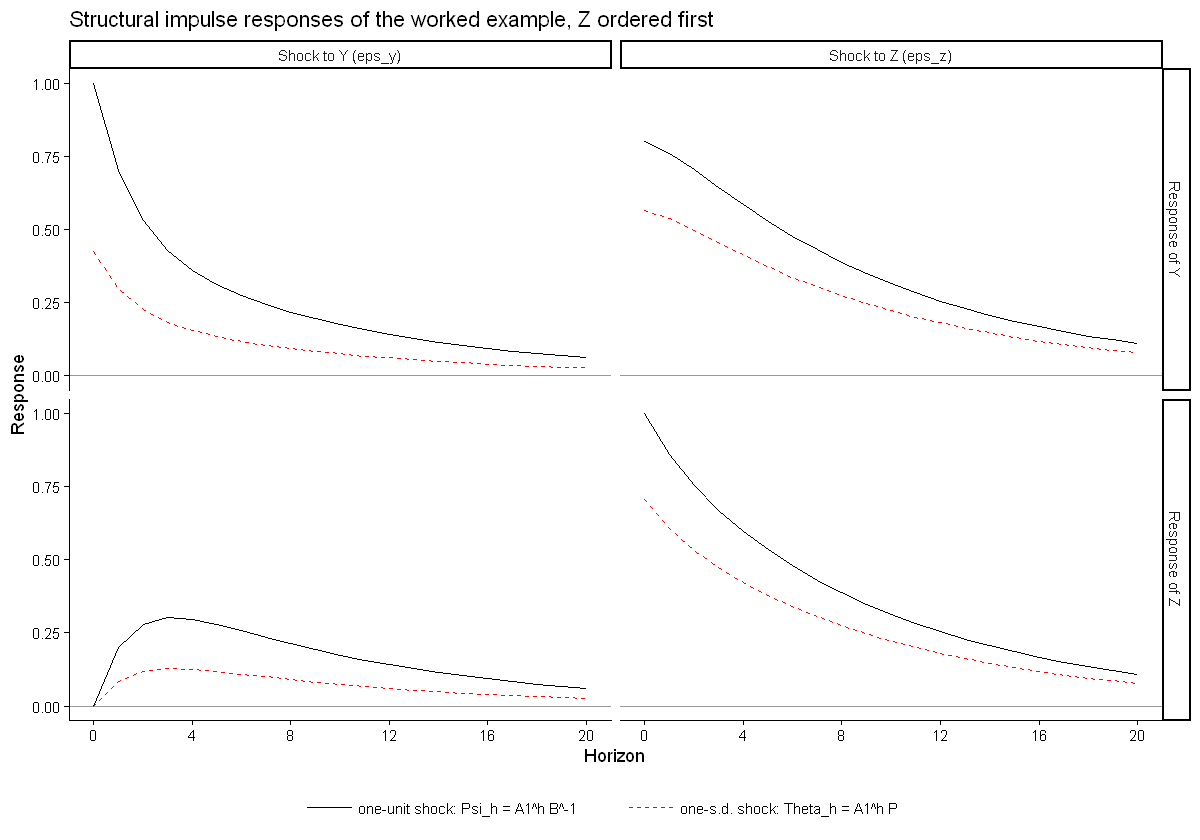

In [15]:
# Step 6: structural impulse responses Psi_h = A1^h B^-1 (one-unit shocks) and Theta_h = A1^h P (one s.d.)
H <- 20
Phi_ex   <- vma(list(A1), h = H)                                              # Phi_h = A1^h
Psi_ex   <- array(apply(Phi_ex, 3, function(F) F %*% Binv), dim(Phi_ex))      # one-unit shocks
Theta_ex <- array(apply(Phi_ex, 3, function(F) F %*% P),    dim(Phi_ex))      # one-s.d. shocks
irf_tab <- data.frame(h = 0:H,
                      `Y to eps_y` = Psi_ex[1, 1, ], `Z to eps_y` = Psi_ex[2, 1, ],
                      `Y to eps_z` = Psi_ex[1, 2, ], `Z to eps_z` = Psi_ex[2, 2, ],
                      check.names = FALSE)
cat("Responses to one-unit structural shocks, Psi_h:\n")
print(round(irf_tab[c(1:5, 9, 13, 21), ], 3), row.names = FALSE)
cat("\nOne-s.d. responses Theta_h = one-unit responses times (sigma_eps_y, sigma_eps_z) = (",
    paste(round(sd_eps, 4), collapse = ", "), ")\n")
LR_cum <- solve(diag(2) - A1) %*% Binv; rownames(LR_cum) <- c("Y", "Z")
cat("Long-run cumulated one-unit responses, (I - A1)^-1 B^-1:\n"); print(round(LR_cum, 3))

options(repr.plot.height = 7)
irf_grid(list(`one-unit shock: Psi_h = A1^h B^-1` = Psi_ex, `one-s.d. shock: Theta_h = A1^h P` = Theta_ex),
         shocks = c("Shock to Y (eps_y)", "Shock to Z (eps_z)"),
         title = "Structural impulse responses of the worked example, Z ordered first")

**Reading the output.** The table reproduces the hand calculations: $(1,\,0,\,0.8,\,1)$ on impact, $(0.7,\,0.2,\,0.76,\,0.86)$ at $h=1$ and $(0.53,\,0.28,\,0.704,\,0.754)$ at $h=2$. After a few periods the responses to each shock become almost identical for $Y$ and $Z$ (both $0.141$ to $\varepsilon_y$ and both $0.254$ to $\varepsilon_z$ at $h=12$) and decline by the factor $0.9$ per period: the eigenvector of the eigenvalue $0.9$ is $(1,1)'$, so the slow component moves $Y$ and $Z$ together, while the fast component (eigenvalue $0.5$, eigenvector $(1,-1)'$) dies out within a few periods.

A one-unit $\varepsilon_z$ shock has the larger and more persistent effect on $Y$ (0.8 on impact and 0.254 at $h=12$, against 1.0 and 0.141 for $\varepsilon_y$), because it moves $Z$ as well and $Z$ feeds back into $Y$. Scaling to one standard deviation reinforces this: $\varepsilon_z$ is the larger shock ($\sigma_{\varepsilon z}=0.707$ against $\sigma_{\varepsilon y}=0.424$), so the dashed red lines for $\varepsilon_y$ shrink to 42% of the one-unit responses while those for $\varepsilon_z$ shrink only to 71%. The long-run cumulated responses, $(I-A_1)^{-1}B^{-1}=\begin{bmatrix}6&8.8\\4&9.2\end{bmatrix}$, are large because the dominant eigenvalue is close to one.

## Step 7: the variance decomposition

At $n=1$ the forecast error is $\Theta_0u_{t+1}=Pu_{t+1}$ (Section 11). The one-step forecast-error variance of $Y$ is therefore $0.4243^2+0.5657^2=0.18+0.32=0.5=\sigma_1^2$, of which $\varepsilon_y$ contributes $0.18/0.5=36\%$ and $\varepsilon_z$ contributes $0.32/0.5=64\%$. For $Z$ the one-step variance is $0.7071^2=0.5$, all of it from $\varepsilon_z$: the recursive restriction rules out any contemporaneous effect of $\varepsilon_y$ on $Z$.

### Predict

As the horizon grows, will the share of $\varepsilon_z$ in the forecast-error variance of $Y$ rise or fall? Will $\varepsilon_y$ ever account for much of the variance of $Z$?

In [16]:
# Step 7: forecast-error variance decomposition, Z ordered first (percentages)
fv_zy <- fevd_table(Theta_ex, horizons = c(1, 2, 4, 8, 12, 20))
print(fv_zy, row.names = FALSE)

 variable n-step    FEV % eps_y % eps_z
        Y      1 0.5000    36.0    64.0
        Y      2 0.8770    30.6    69.4
        Y      4 1.4153    24.8    75.2
        Y      8 1.9962    20.9    79.1
        Y     12 2.2462    19.7    80.3
        Y     20 2.4001    19.0    81.0
        Z      1 0.5000     0.0   100.0
        Z      2 0.8770     0.8    99.2
        Z      4 1.4153     2.7    97.3
        Z      8 1.9962     4.5    95.5
        Z     12 2.2462     5.1    94.9
        Z     20 2.4001     5.4    94.6


**Reading the output.** At $n=1$ the shares are those computed by hand: $Y$ is 36% $\varepsilon_y$ and 64% $\varepsilon_z$; $Z$ is 100% $\varepsilon_z$. The forecast-error variances are $0.5$ for both variables, the diagonal of $\Sigma_e$, and they grow with the horizon (2.40 at $n=20$) towards the unconditional variances. As the horizon lengthens, the share of $\varepsilon_z$ in the forecast-error variance of $Y$ **rises**, to 75% at $n=4$ and 81% at $n=20$, because $\varepsilon_z$ moves $Y$ both directly and through the persistent feedback from $Z$. $\varepsilon_y$ never explains more than about 5% of the variance of $Z$: under this identification $Z$ is close to exogenous with respect to $Y$, and $Y$ is largely driven by $Z$ shocks.

## Step 8: robustness — reverse the ordering

Every conclusion so far rests on $b_{21}=0$. Repeat the analysis with the opposite restriction, $b_{12}=0$ ($Y$ first), and compare.

Cholesky factor with Y first:
   eps_y  eps_z
Y 0.7071 0.0000
Z 0.5657 0.4243
sigma_eps_y^2 = 0.5    sigma_eps_z^2 = 0.18    b21 = -0.8 

Share of the Z shock in each forecast-error variance, under the two orderings:
 variable n-step % eps_z, Z first % eps_z, Y first
        Y      1             64.0              0.0
        Y      4             75.2              2.7
        Y     12             80.3              5.1
        Y     20             81.0              5.4
        Z      1            100.0             36.0
        Z      4             97.3             24.8
        Z     12             94.9             19.7
        Z     20             94.6             19.0


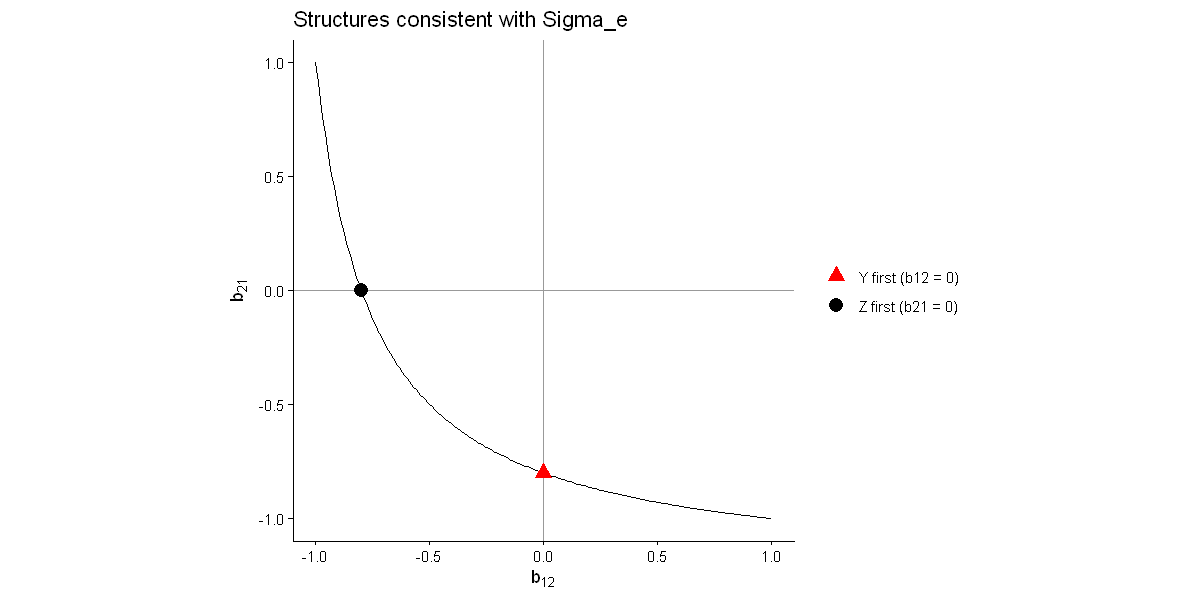

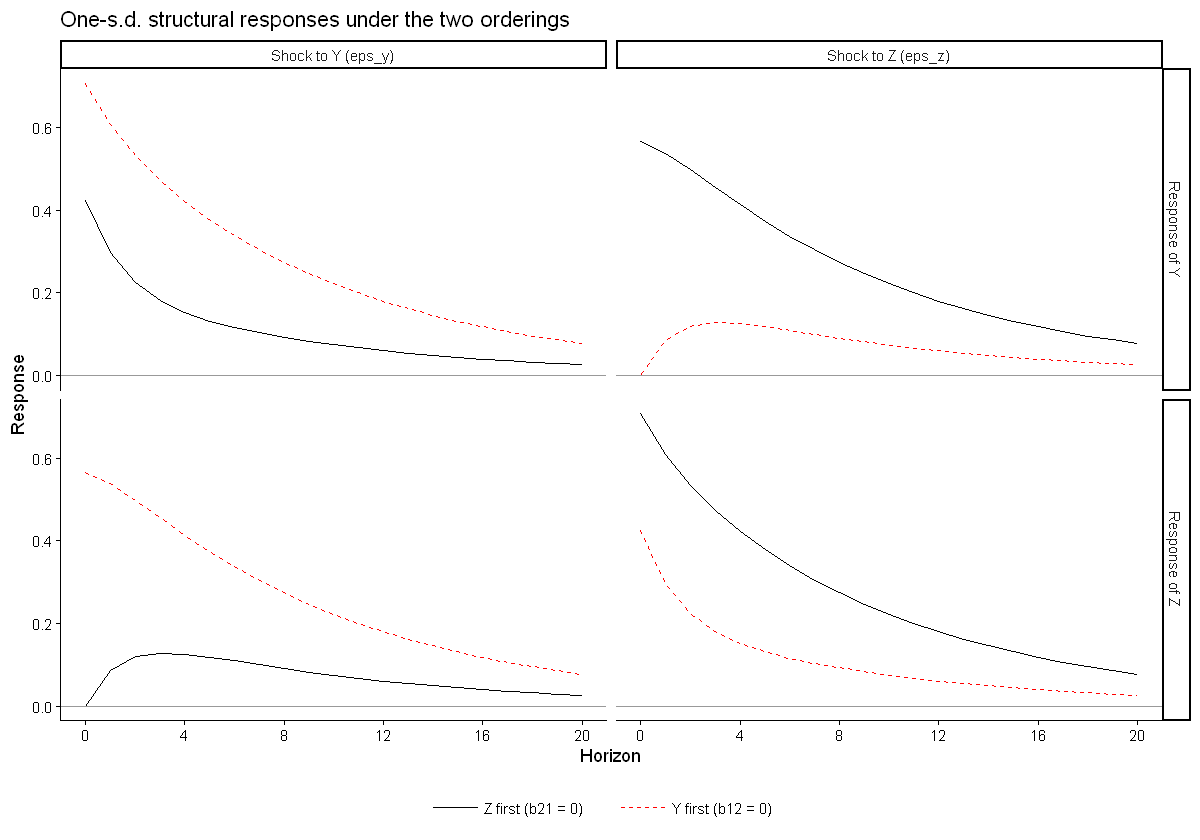

In [17]:
# Step 8: reverse the ordering (Y first, b12 = 0) and compare
P_yz <- t(chol(Sigma_e)); dimnames(P_yz) <- list(c("Y", "Z"), c("eps_y", "eps_z"))
Binv_yz <- sweep(P_yz, 2, diag(P_yz), "/")
cat("Cholesky factor with Y first:\n"); print(round(P_yz, 4))
cat("sigma_eps_y^2 =", round(P_yz[1, 1]^2, 4), "   sigma_eps_z^2 =", round(P_yz[2, 2]^2, 4),
    "   b21 =", round(solve(Binv_yz)[2, 1], 4), "\n\n")

Theta_ex_yz <- array(apply(Phi_ex, 3, function(F) F %*% P_yz), dim(Phi_ex))
h_show <- c(1, 4, 12, 20)
cmp <- cbind(fevd_table(Theta_ex, h_show)[, c(1, 2, 5)],
             fevd_table(Theta_ex_yz, h_show)[, 5])
names(cmp) <- c("variable", "n-step", "% eps_z, Z first", "% eps_z, Y first")
cat("Share of the Z shock in each forecast-error variance, under the two orderings:\n")
print(cmp, row.names = FALSE)

# Every (b12, b21) on this curve reproduces Sigma_e; each ordering picks one point
s1 <- Sigma_e[1, 1]; s2 <- Sigma_e[2, 2]; s12 <- Sigma_e[1, 2]
b21_of <- function(b12) -(s12 + b12 * s2) / (s1 + b12 * s12)
curve <- data.frame(b12 = seq(-1, 1, by = 0.01)); curve$b21 <- b21_of(curve$b12)
pts <- data.frame(b12 = c(-s12 / s2, 0), b21 = c(0, b21_of(0)),
                  ordering = c("Z first (b21 = 0)", "Y first (b12 = 0)"))
options(repr.plot.height = 5)
print(ggplot(curve, aes(b12, b21)) + theme_classic() +
  geom_hline(yintercept = 0, colour = "grey60") + geom_vline(xintercept = 0, colour = "grey60") +
  geom_line() +
  geom_point(data = pts, aes(colour = ordering, shape = ordering), size = 3.5) +
  scale_colour_manual(values = c("red", "black"), name = NULL) +
  scale_shape_manual(values = c(17, 16), name = NULL) + coord_equal() +
  labs(x = expression(b[12]), y = expression(b[21]),
       title = "Structures consistent with Sigma_e"))
options(repr.plot.height = 7)
irf_grid(list(`Z first (b21 = 0)` = Theta_ex, `Y first (b12 = 0)` = Theta_ex_yz),
         shocks = c("Shock to Y (eps_y)", "Shock to Z (eps_z)"),
         title = "One-s.d. structural responses under the two orderings")

**Reading the output.** With $Y$ first, the Cholesky factor is $\begin{bmatrix}0.7071&0\\0.5657&0.4243\end{bmatrix}$, so $\sigma_{\varepsilon y}^2=0.5$, $\sigma_{\varepsilon z}^2=0.18$ and $b_{21}=-0.8$. The conclusions reverse:

- **Variance decomposition.** With $Z$ first, $\varepsilon_z$ explains 64% of the one-step forecast-error variance of $Y$ and 81% at $n=20$; with $Y$ first it explains 0% and 5%. For $Z$ the share of its own shock falls from 100% to 36% at $n=1$.
- **Impulse responses.** Under one ordering $\varepsilon_z$ moves both variables on impact; under the other $\varepsilon_y$ does. Because $A_1$ and $\Sigma_e$ are symmetric in $Y$ and $Z$, the two sets of responses are mirror images of each other, with the roles of $Y$ and $Z$ exchanged. Which variable "drives" the other is decided entirely by the restriction.
- **The identification curve.** Every point on the curve $b_{21}=-(\sigma_{12}+b_{12}\sigma_2^2)/(\sigma_1^2+b_{12}\sigma_{12})$ reproduces $\Sigma_e$ — it is the condition that $B\Sigma_eB'$ be diagonal. The two orderings are its intercepts, $(b_{12},b_{21})=(-0.8,\,0)$ and $(0,\,-0.8)$. Any other point — for example $(-0.5,\,-0.5)$, with both variables responding to each other — is equally consistent with the data. Section 13 looks at ways of choosing such a point.

With a residual correlation of $0.8$ the ordering decides the answer. This is the general lesson: check the residual correlations before interpreting orthogonalized results, justify the ordering on economic grounds, and when the correlations are large, report how the conclusions change with the ordering.

## The steps in summary

| Step | Computation | Result in the example |
|---|---|---|
| 1. Reduced form | OLS: $\hat A_1$, $\hat\Sigma_e$; check stability and the residual correlation | eigenvalues 0.9, 0.5; $\rho_{12}=0.8$ |
| 2. Ordering | economic argument: which variable does not respond within the period? | $Z$ first ($b_{21}=0$) |
| 3. Cholesky factor | `t(chol())` of $\hat\Sigma_e$ in the chosen order, then reorder | $P=\begin{bmatrix}0.4243&0.5657\\0&0.7071\end{bmatrix}$ |
| 4. Structure | $D^{1/2}$ from $\operatorname{diag}(P)$; $B^{-1}$ = columns of $P$ divided by their diagonal | $\sigma_{\varepsilon y}^2=0.18$, $\sigma_{\varepsilon z}^2=0.5$, $b_{12}=-0.8$ |
| 5. Coefficients and shocks | $\Gamma_i=BA_i$; $\varepsilon_t=Be_t$ | $c_{11}=0.54$, $c_{12}=-0.36$; $e_{1t}=\varepsilon_{yt}+0.8\varepsilon_{zt}$ |
| 6. Impulse responses | $\Psi_h=\Phi_hB^{-1}$ (one unit) or $\Theta_h=\Phi_hP$ (one s.d.) | impact $(1,0)$ and $(0.8,1)$ |
| 7. Variance decomposition | sums of squared one-s.d. responses | $Y$: 64% $\varepsilon_z$ at $n=1$ |
| 8. Robustness | repeat with other plausible orderings | conclusions reverse |

# 13&nbsp;&nbsp;Beyond a single recursive ordering

Step 8 showed that every point on a curve of $(b_{12},b_{21})$ values reproduces $\Sigma_e$ equally well, and that a recursive ordering simply picks one of the curve's two intercepts. Economic theory rarely delivers a triangular structure. This section looks at other ways of choosing a point.

## Non-recursive short-run restrictions

**Non-recursive** schemes (Bernanke 1986; Sims 1986; Blanchard and Watson 1986) place $k(k-1)/2$ zeros (or other restrictions) where theory suggests, without requiring a triangular pattern.

**Example.** Let $X_t=(y_t,\pi_t,r_t)'$ be output, inflation and the policy rate, with structural equations

$$
\begin{aligned}
y_t   &= -b_{13}\, r_t + \cdots + \varepsilon_{y t} &&\text{(IS: spending responds to the current rate)}\\
\pi_t &= -b_{21}\, y_t + \cdots + \varepsilon_{\pi t} &&\text{(Phillips curve: inflation responds to current output)}\\
r_t   &= -b_{32}\, \pi_t + \cdots + \varepsilon_{r t} &&\text{(policy rule: output data arrive with a lag)}
\end{aligned}
$$

so that

$$
B=\begin{bmatrix}1&0&b_{13}\\b_{21}&1&0\\0&b_{32}&1\end{bmatrix}.
$$

There are three zeros, which satisfies the order condition $k(k-1)/2=3$, but the causal chain $y\to\pi\to r\to y$ is a **cycle**, so no reordering of the variables makes $B$ triangular. This is a genuinely non-recursive system.

> A common mistake is to write down a "non-recursive" pattern that is a recursive ordering in disguise. For instance, zeros at positions (1,3), (2,1) and (2,3) of $P$ are just the Cholesky ordering $(\pi,y,r)$. Always check whether some permutation of the variables makes the zero pattern triangular.

Three practical points:

1. **Rank condition.** Satisfying the order condition is not enough: the Jacobian of $\Sigma_e=B^{-1}DB^{-1\prime}$ with respect to the free parameters must have full rank (Lütkepohl 2005; Rubio-Ramírez, Waggoner and Zha 2010).
2. **Global identification.** The equations are nonlinear. A system can be locally identified and still have several solutions, so results can depend on starting values. Rubio-Ramírez, Waggoner and Zha (2010) give conditions for global identification.
3. **Estimation.** There is no closed form. Estimation is by maximum likelihood over the free elements; `vars::SVAR()` does this (Section 14.7).

## Externally calibrated coefficients

Instead of setting a coefficient to zero, one can fix it at a value taken from outside the VAR. Blanchard and Perotti (2002) identify fiscal shocks by setting the within-quarter elasticity of net taxes to output equal to an estimate built from tax-code information. This is still one short-run restriction, so the model remains exactly identified.

In the bivariate case the remaining parameter has a closed form. Fix $b_{12}$ and require $B\Sigma_eB'$ to be diagonal; the off-diagonal element is $b_{21}(\sigma_1^2+b_{12}\sigma_{12})+\sigma_{12}+b_{12}\sigma_2^2=0$, so

$$
b_{21}=-\,\frac{\sigma_{12}+b_{12}\sigma_2^2}{\sigma_1^2+b_{12}\sigma_{12}} ,
\qquad D=B\Sigma_eB',\qquad P=B^{-1}D^{1/2}.
$$

This is exactly the identification curve of Step 8: the calibration picks the point on the curve, and $b_{12}=0$ is the Cholesky case. Section 14.8 shows how sensitive the results can be to the calibrated value. That sensitivity motivates the set-identification methods of LN16: if we only know a **range** of plausible values, or only the **signs** of some responses, the honest result is a **set** of structural models.

## Other identifying information

Restrictions need not apply to the impact matrix:

1. **Long-run restrictions** — restrictions on the cumulated responses $\sum_h\Psi_h=A(1)^{-1}B^{-1}$. Blanchard and Quah (1989) separate permanent from transitory shocks by assuming that demand shocks have no long-run effect on the level of output (LN15).
2. **Sign restrictions** — require some responses to have given signs for some horizons (Uhlig 2005; Rubio-Ramírez, Waggoner and Zha 2010). These deliver a **set** of structures rather than a single one (LN16).
3. **External instruments** — a variable correlated with one structural shock and uncorrelated with the others identifies that shock's column of $B^{-1}$ (Stock and Watson 2018; LN17).

## Structural VARs in vars: the A-, B- and AB-models

`vars::SVAR()` follows Lütkepohl (2005) and Amisano and Giannini (1997). It writes the structural form as

$$
\mathcal{A}\,X_t=\mathcal{A}_1^{*}X_{t-1}+\cdots+\mathcal{A}_p^{*}X_{t-p}+\mathcal{B}\,u_t,
\qquad u_t\sim(0,I_k),
\qquad\text{so}\qquad
\mathcal{A}e_t=\mathcal{B}u_t,\quad \Sigma_e=\mathcal{A}^{-1}\mathcal{B}\mathcal{B}'\mathcal{A}^{-1\prime}.
$$

Calligraphic letters avoid a clash with our reduced-form $A_i$ and structural $B$. In our notation:

| Model | Normalization | Restrictions placed on | Number needed | Mapping to our notation |
|---|---|---|---|---|
| **A-model** | $\mathcal{B}=I_k$ | $\mathcal{A}$ | $k(k-1)/2$ | $\mathcal{A}=P^{-1}=D^{-1/2}B$ |
| **B-model** | $\mathcal{A}=I_k$ | $\mathcal{B}$ | $k(k-1)/2$ | $\mathcal{B}=P$ |
| **AB-model** | none | $\mathcal{A}$ and $\mathcal{B}$ | $k^2+k(k-1)/2$ | $\mathcal{A}=B$, $\mathcal{B}=D^{1/2}$ |

The required number of restrictions in the AB-model is $2k^2-k(k+1)/2$. Our SVAR is the AB-model with $\operatorname{diag}(\mathcal{A})=1$ ($k$ restrictions) and $\mathcal{B}$ diagonal (another $k(k-1)$), plus the $k(k-1)/2$ identifying restrictions.

- The A-model fixes $\operatorname{Var}(u_t)=I$, so the diagonal of $\mathcal{A}$ is **not** normalized to one: the estimated diagonal is $1/\sigma_{\varepsilon i}$, hence the large numbers in its output.
- In the restriction matrices, `NA` marks a free parameter and a number fixes a parameter at that value — 0 for an exclusion restriction, or a calibrated value.

**Two `vars` pitfalls:**

1. **Do not name the restriction matrices `A` or `B`.** The bootstrap inside `irf()` re-evaluates the original `SVAR()` call, and those names are resolved to objects inside **vars** rather than to your matrices. The result is the error *"No parameters provided for optimisation"*. Use names such as `amat` and `bmat`.
2. **`Sigma.U` in an `SVAR` object is $\hat\Sigma_e\times100$**, not the covariance of the structural shocks.

# 14&nbsp;&nbsp;Application II: identifying the DIIP–INF VAR

We identify the VAR(3) of Application I, `varest`, with $X_t=(DIIP_t,INF_t)'$, so DIIP is ordered **first**:

- a DIIP shock may move inflation within the quarter;
- an INF shock has no effect on industrial production growth within the quarter.

This is an assumption about **timing**, not about aggregate demand or supply. Cholesky identification here delivers a "DIIP shock" and an "INF shock", not shocks with an economic name; identifying named shocks — for example demand and supply shocks that differ in their long-run effects — needs the restrictions of LN15–LN16. The steps follow the worked example of Section 12, then add the historical decomposition and the `SVAR()` route of Section 13.

## 14.1 The reduced-form covariance and its Cholesky factor

In [18]:
Sigma_hat <- summary(varest)$covres          # reduced-form residual covariance (df-corrected)
signif(Sigma_hat, 4)
cat("Residual correlation:", round(cov2cor(Sigma_hat)[1, 2], 3), "\n")

P_hat  <- t(chol(Sigma_hat))                 # lower-triangular impact matrix: Sigma_e = P P'
D_half <- diag(diag(P_hat))                  # structural standard deviations D^(1/2)
B_hat  <- D_half %*% solve(P_hat)            # contemporaneous matrix B (unit diagonal)
dimnames(P_hat) <- dimnames(B_hat) <- list(colnames(data1), c("DIIP shock", "INF shock"))
signif(P_hat, 4)
round(B_hat, 5)

# Checks: b21 = -sigma_12 / sigma_1^2 (Section 10, Y first) and P P' = Sigma_e
c(b21 = B_hat[2, 1], formula = -Sigma_hat[1, 2] / Sigma_hat[1, 1])
all.equal(P_hat %*% t(P_hat), Sigma_hat, check.attributes = FALSE)

,DIIP,INF
DIIP,1.508e-04,3.18e-06
INF,3.180e-06,3.97e-06


Residual correlation: 0.13 


,DIIP shock,INF shock
DIIP,0.012280,0.000000
INF,0.000259,0.001976


,DIIP shock,INF shock
DIIP,1.00000,0
INF,-0.02109,1


b21     formula 
-0.02108569 -0.02108569

[1] TRUE

**Reading the output.** With the course data

$$
\hat\Sigma_e=\begin{bmatrix}1.508\times10^{-4}&3.18\times10^{-6}\\3.18\times10^{-6}&3.97\times10^{-6}\end{bmatrix},
\qquad
\hat P=\begin{bmatrix}0.01228&0\\0.00026&0.00198\end{bmatrix},
\qquad
\hat B=\begin{bmatrix}1&0\\-0.0211&1\end{bmatrix}.
$$

The structural shocks have standard deviations of about 1.23% (DIIP) and 0.20% (INF) per quarter, and $\hat b_{21}=-\hat\sigma_{12}/\hat\sigma_1^2=-0.0211$: within the quarter, a one-percentage-point rise in industrial production growth raises inflation by about 0.02 points. The residual correlation is

$$
\frac{3.18\times10^{-6}}{\sqrt{1.508\times10^{-4}\times3.97\times10^{-6}}}\approx0.13,
$$

far below the 0.8 of the worked example, so the ordering should matter much less here (Section 14.4).

## 14.2 Structural response matrices $\Theta_h=\Phi_hP$

`vars::Psi()` returns the orthogonalized MA matrices — $\Theta_h$ in our notation, although **vars** calls them $\Psi$ (Section 11). The impact matrix $\Theta_0$ equals $\hat P$.

In [19]:
Theta_hat <- Psi(varest, nstep = 4)          # array: k x k x (nstep + 1)
Phi_hat   <- Phi(varest, nstep = 4)
all.equal(Theta_hat[, , 1], unname(P_hat))                          # Theta_0 = P
all.equal(Theta_hat[, , 3], Phi_hat[, , 3] %*% unname(P_hat))       # Theta_2 = Phi_2 P
signif(Theta_hat[, , 1:2], 3)

[1] TRUE

[1] TRUE

, , 1

         [,1]    [,2]
[1,] 0.012300 0.00000
[2,] 0.000259 0.00198

, , 2

         [,1]     [,2]
[1,] 0.007620 -0.00104
[2,] 0.000664  0.00111

## 14.3 Impulse responses with bootstrap bands

`irf()` computes $\hat\Theta_h$ for $h=0,\dots,H$, with residual-bootstrap percentile bands. We report 68% bands, which are common in macroeconomics; 90% and 95% bands are also widely used. Percentile bootstrap intervals can be biased in small samples because the VAR coefficients themselves are biased towards zero; Kilian (1998) proposes a bias-corrected bootstrap, and Bayesian credible sets are a popular alternative (Kilian and Lütkepohl 2017, Ch. 12). Responses are plotted in percentage points (log changes $\times100$).

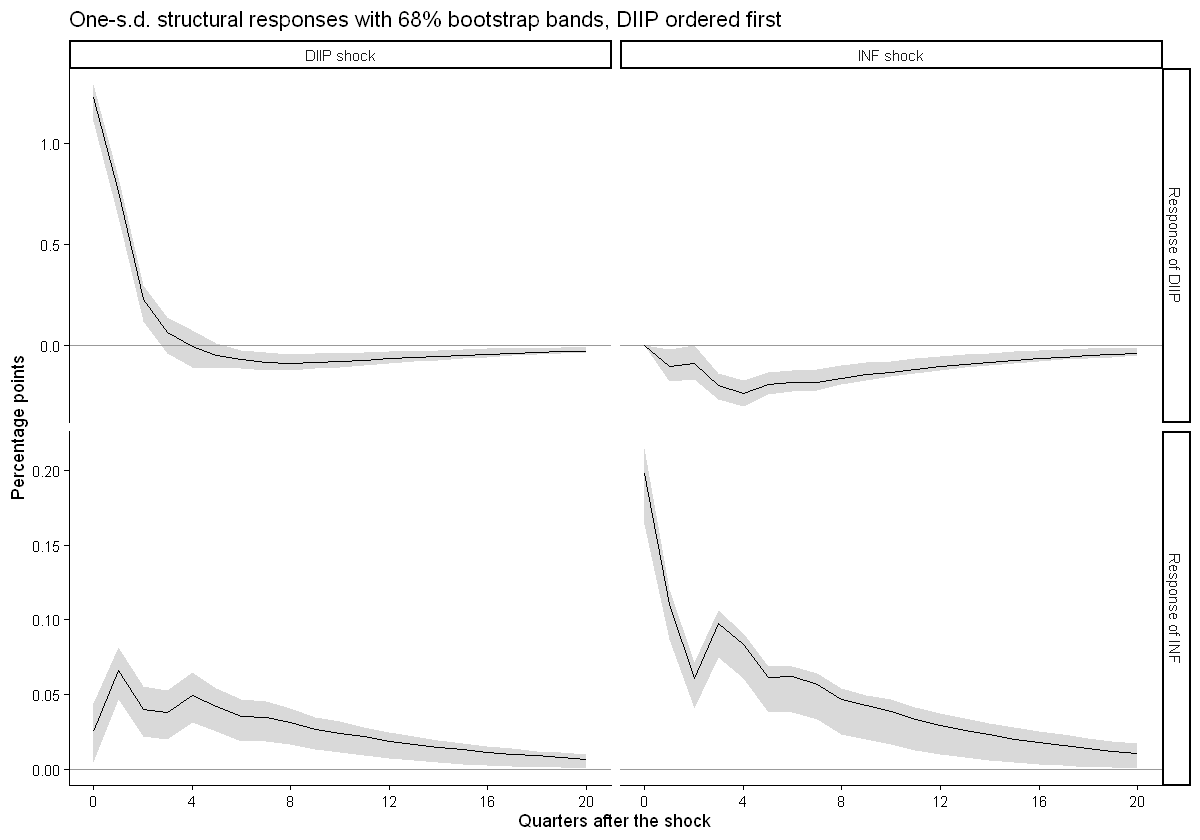

In [20]:
set.seed(123)
ir_chol <- irf(varest, n.ahead = 20, ortho = TRUE, boot = TRUE, runs = 500, ci = 0.68)
options(repr.plot.height = 7)
irf_grid(list(`DIIP first` = 100 * irf_array(ir_chol)),
         vars = c("DIIP", "INF"), shocks = c("DIIP shock", "INF shock"),
         lower = 100 * irf_array(ir_chol, "Lower"), upper = 100 * irf_array(ir_chol, "Upper"),
         xlab = "Quarters after the shock", ylab = "Percentage points",
         title = "One-s.d. structural responses with 68% bootstrap bands, DIIP ordered first")

**What to look for.**

- **DIIP shock.** It raises DIIP on impact by one standard deviation, about 1.2 percentage points. The small positive impact effect on inflation, $\hat P_{21}\approx0.03$ points, follows from the positive residual correlation.
- **INF shock.** Its impact effect on DIIP is zero *by assumption*. Its effect on DIIP in later quarters reflects the negative lagged coefficients of INF in the DIIP equation ($\hat\phi_{12,1}=-0.53$ in Section 8.5).
- **Convergence.** All responses return to zero because the VAR is stable (largest companion root 0.884).

## 14.4 Does the ordering matter?

### Predict

With a residual correlation of about 0.13, how much of the one-step forecast-error variance of INF can the DIIP shock explain when DIIP is ordered first? How much of DIIP's can the INF shock explain when INF is ordered first? (Hint: in a bivariate Cholesky decomposition the later variable's one-step share from the earlier shock is $\rho_{12}^2$.)

Impact matrix, DIIP first (INF shock has no impact effect on DIIP):
     DIIP shock INF shock
DIIP   0.012300   0.00000
INF    0.000259   0.00198

Impact matrix, INF first (DIIP shock has no impact effect on INF):
     DIIP shock INF shock
DIIP     0.0122   0.00160
INF      0.0000   0.00199


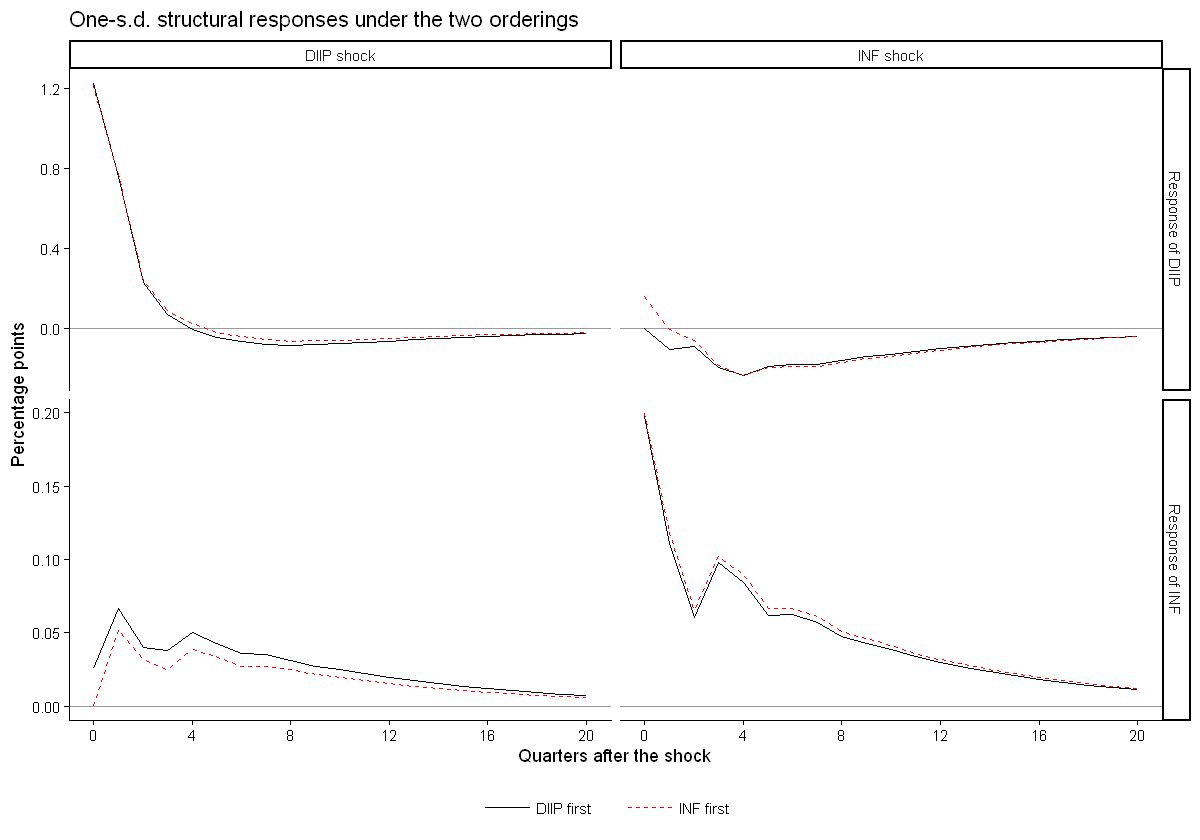

In [21]:
varest_rev <- VAR(data1[, c("INF", "DIIP")], p = p_sel, type = "const")
P_rev <- t(chol(summary(varest_rev)$covres))[c("DIIP", "INF"), c("DIIP", "INF")]
dimnames(P_rev) <- dimnames(P_hat)
cat("Impact matrix, DIIP first (INF shock has no impact effect on DIIP):\n"); print(signif(P_hat, 3))
cat("\nImpact matrix, INF first (DIIP shock has no impact effect on INF):\n"); print(signif(P_rev, 3))

ir_rev  <- irf(varest_rev, n.ahead = 20, ortho = TRUE, boot = FALSE)
irf_rev <- irf_array(ir_rev)[c("DIIP", "INF"), c("DIIP", "INF"), ]    # back to the order (DIIP, INF)
options(repr.plot.height = 7)
irf_grid(list(`DIIP first` = 100 * irf_array(ir_chol), `INF first` = 100 * irf_rev),
         vars = c("DIIP", "INF"), shocks = c("DIIP shock", "INF shock"),
         xlab = "Quarters after the shock", ylab = "Percentage points",
         title = "One-s.d. structural responses under the two orderings")

**Reading the output.** The two impact matrices differ only in which off-diagonal element is set to zero, and the free off-diagonal element is small either way. On impact the "other" shock explains $\rho_{12}^2\approx0.13^2\approx2\%$ of the one-step forecast-error variance under either ordering, and the two sets of impulse responses lie almost on top of each other. Contrast Step 8 of Section 12, where a correlation of 0.8 reversed every conclusion: here the timing assumption is cheap, because the data leave little contemporaneous comovement to allocate.

## 14.5 Forecast-error variance decomposition

,% DIIP shock,% INF shock
n = 1,100.0,0.0
n = 4,97.5,2.5
n = 10,89.4,10.6
n = 20,87.0,13.0
,% DIIP shock,% INF shock
n = 1,1.7,98.3
n = 4,11.2,88.8
n = 10,16.1,83.9
n = 20,17.2,82.8


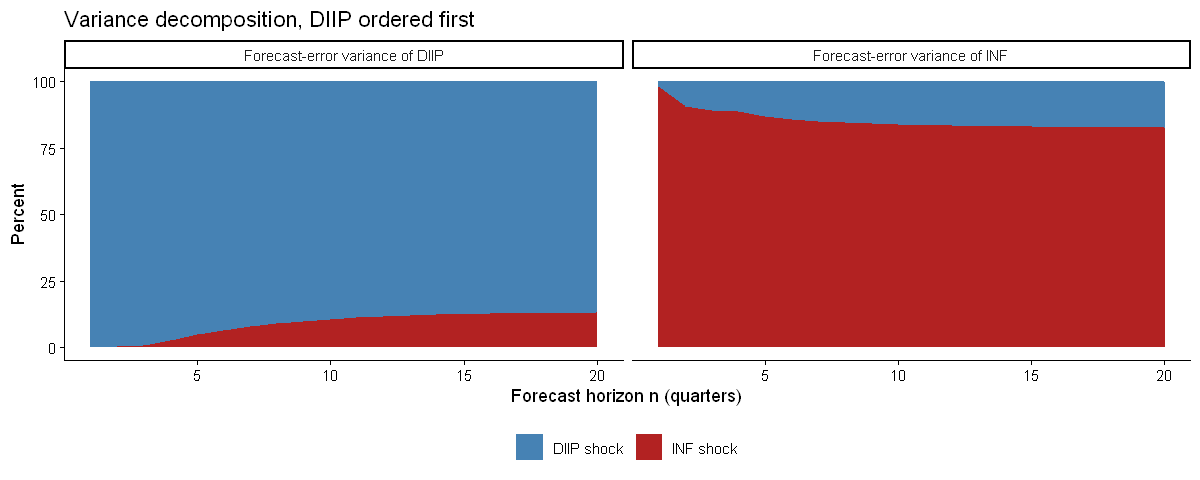

In [22]:
fevd_chol <- fevd(varest, n.ahead = 20)
fevd_rows <- c(1, 4, 10, 20)
lapply(fevd_chol, function(m) {
  x <- round(100 * m[fevd_rows, ], 1)
  dimnames(x) <- list(paste0("n = ", fevd_rows), paste("%", colnames(m), "shock"))
  x
})

fe_df <- do.call(rbind, lapply(names(fevd_chol), function(v) {
  m <- fevd_chol[[v]]
  data.frame(variable = paste("Forecast-error variance of", v),
             horizon  = rep(seq_len(nrow(m)), ncol(m)),
             shock    = factor(rep(paste(colnames(m), "shock"), each = nrow(m)),
                               levels = paste(colnames(m), "shock")),
             share    = 100 * c(m))
}))
options(repr.plot.height = 4)
print(ggplot(fe_df, aes(horizon, share, fill = shock)) + theme_classic() +
  geom_area() + facet_wrap(~ variable) +
  scale_fill_manual(values = c("steelblue", "firebrick"), name = NULL) +
  labs(x = "Forecast horizon n (quarters)", y = "Percent", title = "Variance decomposition, DIIP ordered first") +
  theme(legend.position = "bottom"))
options(repr.plot.height = 6)

**Reading the output.** With the course data:

- **DIIP shocks dominate DIIP's own forecast-error variance**: 100% at $n=1$ (by construction, since DIIP is ordered first) and still about 89% at ten quarters.
- **INF shocks explain about 11% of DIIP's variance at ten quarters**, starting from zero at $n=1$ by construction.
- **DIIP shocks explain about 2% of inflation's variance at $n=1$** — the $\rho_{12}^2$ of Section 14.4 — rising to about 16% at ten quarters.

Both variables are therefore driven mainly by their own innovations, with a modest feedback from industrial production into inflation. Because the residual correlation is small, these shares hardly depend on the ordering (Exercise 5).

## 14.6 Historical decomposition

`hist_decomp()` implements the formula of Section 11:

1. recover the structural shocks $\hat u_t=\hat P^{-1}\hat e_t$;
2. accumulate each shock's contribution through $\hat\Theta_s=\hat\Phi_s\hat P$;
3. compute the baseline by iterating the VAR forward from the first $p$ observations with every shock set to zero.

The check in the first line is not automatic: it confirms that baseline plus contributions reproduces the data exactly.

[1] TRUE

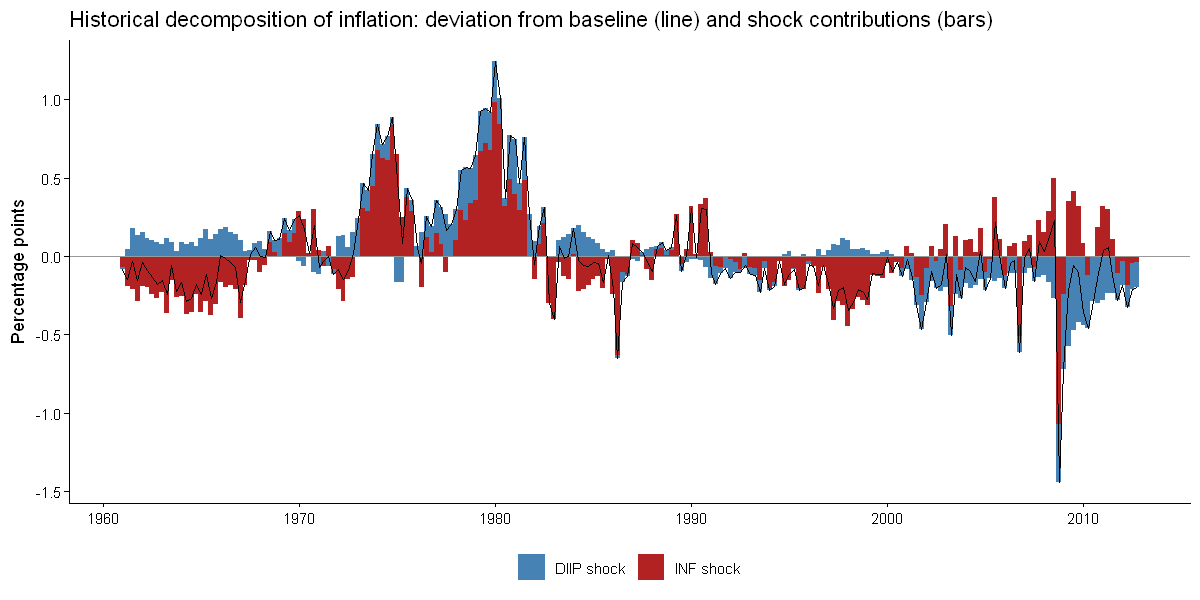

In [23]:
hd <- hist_decomp(varest, P_hat)
# Check: baseline + contributions of the two shocks = the data
all.equal(hd$baseline + apply(hd$contrib, c(1, 2), sum), hd$actual, check.attributes = FALSE)

tt_hd  <- as.numeric(time(data1))[-(1:varest$p)]
hd_df  <- data.frame(date  = rep(tt_hd, 2),
                     shock = factor(rep(dimnames(hd$contrib)[[3]], each = length(tt_hd))),
                     value = 100 * c(hd$contrib[, "INF", 1], hd$contrib[, "INF", 2]))
dev_df <- data.frame(date = tt_hd, value = 100 * (hd$actual[, "INF"] - hd$baseline[, "INF"]))
options(repr.plot.height = 5)
print(ggplot() + theme_classic() +
  geom_col(data = hd_df, aes(date, value, fill = shock), width = 0.25) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_line(data = dev_df, aes(date, value)) +
  scale_fill_manual(values = c("steelblue", "firebrick"), name = NULL) +
  labs(x = NULL, y = "Percentage points",
       title = "Historical decomposition of inflation: deviation from baseline (line) and shock contributions (bars)") +
  theme(legend.position = "bottom"))
options(repr.plot.height = 6)

**Reading the output.** The black line is inflation minus its baseline; the bars split it into the cumulated contributions of the two structural shocks, which add up to the line in every quarter. Look at the episodes you know — the inflation surges of 1973–75 and 1979–81, the disinflation of the early 1980s — and ask which shock the identified model credits with them. With DIIP ordered first and a residual correlation of only 0.13, inflation's own shock should account for most of its movements, with DIIP shocks contributing through the lagged feedback in the VAR. Remember that the labels are timing-based: the "INF shock" here bundles every disturbance that moves inflation but not industrial production within the quarter, oil-price shocks included.

## 14.7 The same identification with `SVAR()`

The three specifications of Section 13 all impose the recursive ordering with DIIP first, so they must reproduce the Cholesky results. The restriction matrices are named `amat` and `bmat`, not `A` and `B`.

In [24]:
k <- 2
# SVAR() warns that a just-identified model has no over-identification test; that is expected here.

# A-model: B = I, A lower triangular (free diagonal, because Var(u) = I in vars)
amat <- matrix(NA, k, k); amat[upper.tri(amat)] <- 0
svar_a <- suppressWarnings(SVAR(varest, Amat = amat, estmethod = "direct"))

# B-model: A = I, B lower triangular
bmat <- matrix(NA, k, k); bmat[upper.tri(bmat)] <- 0
svar_b <- suppressWarnings(SVAR(varest, Bmat = bmat, estmethod = "direct"))

# AB-model: A unit lower triangular (our B), B diagonal (our D^(1/2))
amat_ab <- diag(k); amat_ab[lower.tri(amat_ab)] <- NA
bmat_ab <- diag(NA, k); bmat_ab[!diag(k)] <- 0
svar_ab <- suppressWarnings(SVAR(varest, Amat = amat_ab, Bmat = bmat_ab, estmethod = "direct"))

round(svar_a$A, 3)                             # = P^{-1}: diagonal = 1/sigma_eps
# SVAR() maximizes the likelihood numerically, so agreement is to optimizer precision
all.equal(unname(solve(svar_a$A)), unname(P_hat), tolerance = 1e-3)
all.equal(unname(svar_b$B), unname(P_hat), tolerance = 1e-3)
round(svar_ab$A, 5); signif(svar_ab$B, 4)      # = our B and D^(1/2)

,DIIP,INF
DIIP,81.415,0.00
INF,-10.681,506.18


[1] TRUE

[1] TRUE

,DIIP,INF
DIIP,1.00000,0
INF,-0.02108,1


,DIIP,INF
DIIP,0.01228,0.000000
INF,0.00000,0.001976


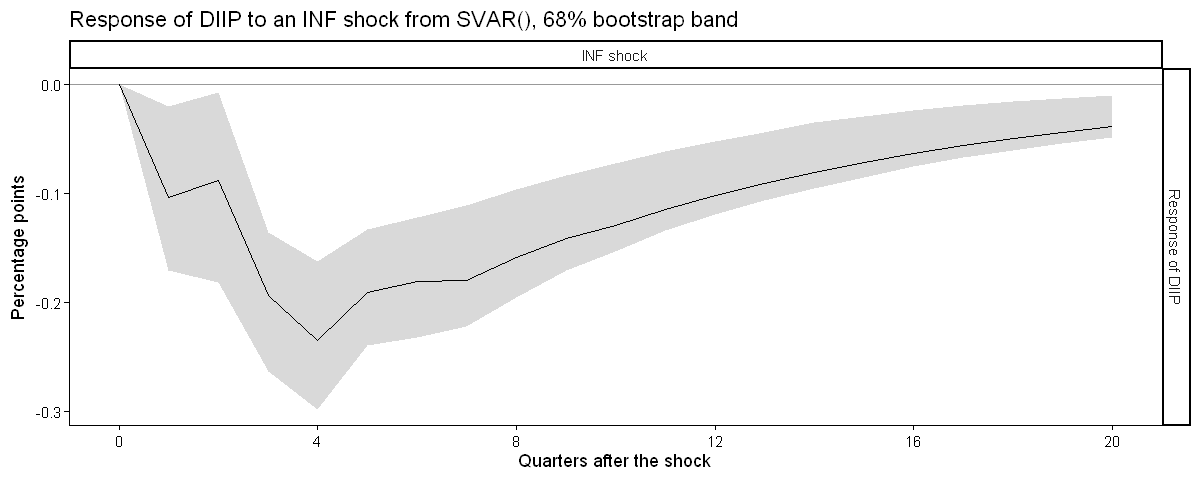

In [25]:
# Bootstrap IRFs from an SVAR object work because the restriction matrix is not called "A".
# Each replication re-estimates the SVAR and repeats the "just identified" warning, so we suppress it.
set.seed(123)
ir_a <- suppressWarnings(irf(svar_a, impulse = "INF", response = "DIIP", n.ahead = 20,
                             boot = TRUE, runs = 200, ci = 0.68))
options(repr.plot.height = 4)
irf_grid(list(`SVAR A-model` = 100 * irf_array(ir_a)), vars = "DIIP", shocks = "INF shock",
         lower = 100 * irf_array(ir_a, "Lower"), upper = 100 * irf_array(ir_a, "Upper"),
         xlab = "Quarters after the shock", ylab = "Percentage points",
         title = "Response of DIIP to an INF shock from SVAR(), 68% bootstrap band")

**Reading the output.** `solve(svar_a$A)` and `svar_b$B` both equal $\hat P$, and the AB-model returns $\hat B$ (unit diagonal, $\hat b_{21}\approx-0.021$) and $\hat D^{1/2}$ (the structural standard deviations on the diagonal). The response of DIIP to the INF shock matches the corresponding panel of Section 14.3. For a just-identified recursive model `SVAR()` adds nothing to `t(chol())`; its value lies in non-recursive and over-identified models, where there is no closed form.

## 14.8 A calibrated non-recursive restriction and its sensitivity

Suppose outside evidence fixed the **within-quarter effect of inflation on industrial production**. In the AB-model the DIIP equation is

$$
DIIP_t=-b_{12}\,INF_t+\cdots+\sigma_{\varepsilon1}u_{1t},
$$

and we fix $b_{12}$ at a calibrated value while leaving $b_{21}$ free — the Blanchard–Perotti strategy of Section 13. The closed form of Section 13 gives $b_{21}$, $D$ and $P$ for each calibration; $b_{12}=0$ is the Cholesky case. The loop below shows how the impact responses depend on the calibrated value.

> **Practical note.** `SVAR(varest, Amat = ..., Bmat = ...)` with a fixed non-zero element estimates the same model numerically. With variables measured as log changes (variances around $10^{-4}$ to $10^{-6}$), the optimizer can stop far from the optimum. Rescaling the data to percent (`100 * data1`) before estimating helps, and in small systems it pays to verify against the closed form.

In [26]:
calibrated_P <- function(b12, S) {
  b21 <- -(S[1, 2] + b12 * S[2, 2]) / (S[1, 1] + b12 * S[1, 2])
  Bc  <- matrix(c(1,   b12,
                  b21, 1), 2, byrow = TRUE)
  Dc  <- Bc %*% S %*% t(Bc)                      # diagonal by construction
  list(b21 = b21, P = solve(Bc) %*% diag(sqrt(diag(Dc))))
}

b12_grid <- c(-2, -1, -0.5, 0, 0.5, 1, 2)
sens <- t(sapply(b12_grid, function(b12) {
  cp <- calibrated_P(b12, Sigma_hat)
  c(b12 = b12, b21 = cp$b21,
    DIIP_to_shock1 = cp$P[1, 1], INF_to_shock1 = cp$P[2, 1],
    DIIP_to_shock2 = cp$P[1, 2], INF_to_shock2 = cp$P[2, 2])
}))
signif(sens, 3)

# Every calibration reproduces Sigma_e exactly
sapply(b12_grid, function(b) {
  Pb <- calibrated_P(b, Sigma_hat)$P
  isTRUE(all.equal(Pb %*% t(Pb), Sigma_hat, check.attributes = FALSE))
})

b12,b21,DIIP_to_shock1,INF_to_shock1,DIIP_to_shock2,INF_to_shock2
-2.0,0.03290,0.0116,-3.84e-04,0.003910,0.00196
-1.0,0.00535,0.0121,-6.48e-05,0.001990,0.00199
-0.5,-0.00801,0.0122,9.80e-05,0.000995,0.00199
0.0,-0.02110,0.0123,2.59e-04,0.000000,0.00198
0.5,-0.03390,0.0122,4.15e-04,-0.000974,0.00195
1.0,-0.04640,0.0121,5.63e-04,-0.001910,0.00191
2.0,-0.07070,0.0117,8.30e-04,-0.003620,0.00181


[1] TRUE TRUE TRUE TRUE TRUE TRUE TRUE

**Reading the output.** Every row is an **equally good fit to the data**: each reproduces $\hat\Sigma_e$ exactly, as the final line confirms. Yet the implied impact responses differ. In particular, the impact response of DIIP to the second shock has the opposite sign to $b_{12}$, so it flips sign as the calibration crosses zero, the Cholesky case.

The data cannot tell these structures apart; only the calibration chooses among them — the same lesson as the identification curve of Section 12, now with real data. If we are honest that we only know a *range* of plausible values, or only the *signs* of some responses, the natural result is a **set** of structural models (LN16).

# Summary

**Part I — the reduced-form VAR.**

- A VAR treats every variable as endogenous. The structural VAR $BX_t=\Gamma_0+\Gamma_1X_{t-1}+\varepsilon_t$ cannot be estimated by OLS, because the contemporaneous terms are correlated with the shocks; the reduced form $X_t=A_0+A_1X_{t-1}+e_t$ can, equation by equation.
- The reduced-form errors $e_t=B^{-1}\varepsilon_t$ are white noise but are mixtures of the structural shocks, and are correlated across equations.
- A VAR is stable — and covariance stationary — when all companion eigenvalues lie inside the unit circle. A stable VAR has a Wold (VMA) representation $X_t=\mu+\sum_h\Phi_he_{t-h}$, which delivers the mean, the variance, the forecast errors and the forecast-error impulse responses.
- Choose the lag length with information criteria or LR tests on a common sample, and check stability and residual autocorrelation. Granger causality is about predictability, not structural causation; forecasting needs only the reduced form.

**Part II — identification and innovation accounting.**

- The reduced form identifies $\Sigma_e$ but not $(B,D)$: $k(k-1)/2$ restrictions are needed (the order condition), and the rank condition must also hold. Equivalently, any rotation $PQ$ of a factor $P$ of $\Sigma_e$ fits the data equally well.
- **Recursive identification** amounts to a Cholesky decomposition of $\Sigma_e$. It is exactly identified for a *given ordering*, and the ordering is an economic assumption about within-period timing. It matters most when the residual correlations are large (0.8 in the worked example) and little when they are small (0.13 in the application).
- **Innovation accounting** describes the identified model: impulse responses $\Psi_h=\Phi_hB^{-1}$ and $\Theta_h=\Phi_hP$ trace the propagation of shocks; variance decompositions measure each shock's contribution to forecast uncertainty; historical decompositions attribute observed episodes to shocks.
- **Non-recursive** schemes and calibrated coefficients use theory more directly, but need care with rank and global identification and can be very sensitive to the imposed values. In **vars**, `SVAR()` estimates the A-, B- and AB-models; do not name the restriction matrices `A` or `B`.

> "Monetary policy tries to control inflation, and as a result interest rates tend to be high when inflation is high. But we think that raising interest rates lowers inflation. The main contribution of this work is to provide a way to untangle the relationship between interest rates and inflation …" — Christopher Sims, interview, 10 October 2011.

## Exercises

### Exercise 1 — From structure to reduced form (Sections 2–3, 10)
Let $b_{12}=0.5$, $b_{21}=0$, $\sigma_{\varepsilon y}^2=\sigma_{\varepsilon z}^2=1$ and $\Gamma_1=\begin{bmatrix}0.6&0.2\\0.1&0.5\end{bmatrix}$. (a) Compute $B^{-1}$, $A_1=B^{-1}\Gamma_1$ and $\Sigma_e$. (b) Which variable responds within the period to which shock? (c) Compute $\Psi_0$ and $\Psi_1$. (d) Show that the Cholesky factorization with $Z$ ordered first recovers $B$ exactly, while ordering $Y$ first does not. Check your answers with `solve()`, `chol()` and `vma()`.

### Exercise 2 — Stability (Section 4)
Let $A_1=\begin{bmatrix}0.8&a\\0.2&0.6\end{bmatrix}$. (a) Write $\det(I-A_1z)$ as a function of $a$. (b) For which value of $a$ does the VAR have a unit root? (c) For which values of $a$ is it stable? (Hint: the eigenvalues are real for some values of $a$ and complex for others.) (d) Check your answers with `eigen()` for a grid of values of $a$.

### Exercise 3 — Lag length (Section 6)
A three-variable VAR with intercepts is estimated on $T=200$ usable observations. With 4 lags, $\ln|\hat\Sigma_u|=-15.40$; with 2 lags on the same sample, $\ln|\hat\Sigma_r|=-15.20$. (a) Compute the LR statistic, its degrees of freedom and the 5% critical value. (b) Compute AIC and SBC for both lag lengths. (c) Which lag length does each criterion choose, and why might they disagree?

### Exercise 4 — Cholesky identification and variance decomposition by hand (Sections 10–12)
A bivariate VAR(1) has $\hat A_1=\begin{bmatrix}0.5&0.1\\0.2&0.6\end{bmatrix}$ and $\hat\Sigma_e=\begin{bmatrix}1.0&0.5\\0.5&2.0\end{bmatrix}$. (a) Compute the Cholesky factor for the ordering $(Y,Z)$ and for $(Z,Y)$, and the implied $b_{12}$, $b_{21}$, $\sigma_{\varepsilon y}^2$ and $\sigma_{\varepsilon z}^2$. (b) Compute the one-unit structural responses $\Psi_0$ and $\Psi_1$ under each ordering. (c) Compute the one- and two-step variance decompositions of both variables under each ordering. (d) Suppose $Y$ is a policy interest rate set by a central bank that observes $Z$, a monthly activity indicator, only with a one-month lag. Which ordering would you use for monthly data, and why?

### Exercise 5 — The application (Sections 8 and 14)
(a) Re-estimate the VAR with the 5 lags chosen by AIC. Do the diagnostics, the impulse responses and the variance decomposition at ten quarters change much? (b) Recompute the variance decomposition of Section 14.5 with INF ordered first (`fevd(varest_rev)`) and compare the shares at ten quarters. Relate the difference to the instantaneous-causality test of Section 8.4 and to the residual correlation of Section 14.1. (c) In Section 14.8, which sign of $b_{12}$ corresponds to "higher inflation lowers industrial production growth within the quarter"? Is there an economic argument for that sign, and how large would $|b_{12}|$ have to be to change the conclusions of Section 14.5 materially?

## Suggested reading

- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 5 (the primitive and standard-form VAR, stability, identification, impulse responses, variance decomposition, lag length — the basis of this lecture).
- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Chs. 10–11 (covariance-stationary vector processes; estimation, Granger causality, impulse responses and variance decompositions of VARs).
- Lütkepohl, H. (2005), *New Introduction to Multiple Time Series Analysis*, Springer: Chs. 2–4 (stable VAR processes, estimation, lag-order selection and diagnostics) and Ch. 9 (structural VARs).
- Kilian, L. and Lütkepohl, H. (2017), *Structural Vector Autoregressive Analysis*, Cambridge University Press — the modern reference on identification (Chs. 2–4, 8 and 12).
- Pfaff, B. (2008), *Analysis of Integrated and Cointegrated Time Series with R*, 2nd ed., Springer: Ch. 2 — the companion to **vars**.
- Stock, J. H. and Watson, M. W. (2001), "Vector autoregressions", *Journal of Economic Perspectives* 15(4), 101–115 — a short, readable introduction.

**Original papers.**

*Foundations:* Wold (1938, *A Study in the Analysis of Stationary Time Series*); Zellner (1962, *JASA* 57, 348–368); Granger (1969, *Econometrica* 37, 424–438); Sims (1980, "Macroeconomics and reality", *Econometrica* 48, 1–48).

*Short-run identification:* Bernanke (1986, *Carnegie-Rochester Conference Series on Public Policy* 25); Sims (1986, *Federal Reserve Bank of Minneapolis Quarterly Review* 10(1)); Blanchard and Watson (1986, in Gordon (ed.), *The American Business Cycle*); Amisano and Giannini (1997, *Topics in Structural VAR Econometrics*, 2nd ed., Springer); Christiano, Eichenbaum and Evans (1999, *Handbook of Macroeconomics* 1A); Blanchard and Perotti (2002, *QJE* 117(4)).

*Other identification schemes:* Blanchard and Quah (1989, *AER*); Uhlig (2005, *JME*); Rubio-Ramírez, Waggoner and Zha (2010, *REStud* 77(2)); Stock and Watson (2018, *Economic Journal*).

*Inference on impulse responses:* Kilian (1998, *REStat* 80(2)).

*Software:* Pfaff (2008), "VAR, SVAR and SVEC models: implementation within R package vars", *Journal of Statistical Software* 27(4).

*Surveys:* Ramey (2016, *Handbook of Macroeconomics* 2A) on macroeconomic shocks and their propagation.

## Appendix A: R quick reference

| Task | Function | Notes |
|---|---|---|
| Cholesky factor | `t(chol(S))` | `chol()` returns the **upper** factor $U$ with $S=U'U$; reorder rows and columns of `S` to change the ordering |
| Eigenvalues and roots | `eigen(A)`, `polyroot()` | roots of $\det(I-A_1z)$ are the reciprocals of the eigenvalues |
| VMA matrices from known $A_i$ | `vma(A, h)` | this lecture's helper: $\Phi_0,\dots,\Phi_h$ |
| Variance decomposition from responses | `fevd_table(Theta, horizons)` | this lecture's helper; `Theta` holds one-s.d. responses $\Theta_h$ |
| Plot impulse responses | `irf_grid(irfs, vars, shocks, lower, upper)`, `irf_array(ir, what)` | this lecture's helpers; `irf_array()` converts `vars::irf()` output |
| Historical decomposition | `hist_decomp(fit, P)` | this lecture's helper; returns actual, baseline and shock contributions |
| Unit-root pre-test | `urca::ur.df(x, type = "drift", lags, selectlags = "AIC")` | Lecture 10 |
| Lag-length selection | `vars::VARselect(y, lag.max, type)` | AIC, HQ, SC (BIC) and FPE on a common sample |
| Estimate a VAR($p$) | `vars::VAR(y, p, type = "const")` | OLS equation by equation; the column order of `y` is the Cholesky ordering; pass `p` explicitly |
| Coefficients | `vars::Acoef(fit)`, `vars::Bcoef(fit)`, `coef(fit)` | $\hat A_i$; all coefficients; estimates with standard errors |
| Residual covariance and correlation | `summary(fit)`, elements `covres` and `corres` | $\hat\Sigma_e$ (degrees-of-freedom corrected) |
| Stability | `vars::roots(fit)` | moduli of the companion eigenvalues; all must be below one |
| Serial correlation | `vars::serial.test(fit, lags.pt, type = "PT.asymptotic")` | also `type = "BG"` for the LM test |
| Normality, ARCH | `vars::normality.test(fit)`, `vars::arch.test(fit)` | |
| Granger and instantaneous causality | `vars::causality(fit, cause)` | elements `$Granger` and `$Instant` |
| Forecasting | `predict(fit, n.ahead, ci)`, `vars::fanchart()` | point forecasts and intervals |
| VMA matrices from a fitted VAR | `vars::Phi(fit, nstep)`, `vars::Psi(fit, nstep)` | $\hat\Phi_h$; $\hat\Theta_h=\hat\Phi_h\hat P$ (Cholesky; **vars** calls it $\Psi$) |
| Impulse responses | `vars::irf(fit, impulse, response, n.ahead, ortho, cumulative, boot, runs, ci)` | `ortho = TRUE`: one-s.d. Cholesky shocks |
| Variance decomposition | `vars::fevd(fit, n.ahead)` | uses the Cholesky ordering, or the identification of an `SVAR` object |
| Short-run SVAR | `vars::SVAR(fit, Amat, Bmat, estmethod = "direct")` | `NA` marks a free coefficient; never name the matrices `A` or `B` |
| Long-run SVAR | `vars::BQ(fit)` | Blanchard–Quah (LN15) |